<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_UniversalAdversarialPerturbation_Anil2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QuGAP: universal adversarial perturbations for quantum classifiers (Anil, Vinod and Narayan, 2024) step by step

This notebook re-implements, runs and checks the experiments of

> Gautham Anil, Vishnu Vinod and Apurva Narayan,
> "Generating Universal Adversarial Perturbations for Quantum Classifiers",
> Proceedings of the AAAI Conference on Artificial Intelligence 38(10), 10891-10899, 2024. https://doi.org/10.1609/aaai.v38i10.28963
> (the authors' code is at https://github.com/Idsl-group/QuGAP; the supplementary material it links to was not available to us).

**What the notebook does.** A *universal* adversarial perturbation (UAP) is one single perturbation that fools a classifier on (almost) every input,
instead of a new perturbation per image. The paper builds two ways of generating UAPs for **parametrised-quantum-circuit (PQC) classifiers**:

* **QuGAP-A (additive).** A classical generator network turns a fixed random vector into one perturbation that is *added to the pixels* of amplitude-encoded
  MNIST / Fashion-MNIST images (16 x 16 pixels, 8 data qubits), with an L-infinity budget epsilon.
* **QuGAP-U (unitary).** A *quantum* generator (a PQC) transforms the quantum state itself, and a fidelity term keeps the attacked state close to the clean one.
  It is tested on pure quantum data (ground states of the transverse-field Ising model) and on 8 x 8 MNIST, against the earlier qBIM attack.

The notebook builds an exact simulator of the PennyLane circuits (checked against the real PennyLane QNodes), trains PQC classifiers of depth 10 / 20 / 40 / 60 and a
classical CNN, generates QuGAP-A perturbations at many budgets, re-draws the paper's Fig. 2, adds controls the paper does not have (per-sample PGD, random-sign UAPs,
transfer to a CNN, a random forest and an SVM), checks the existence theorem numerically, runs QuGAP-U in the paper's classical simulation (Fig. 4) and with PQC generators
(Fig. 5, Table 1) next to a qBIM baseline, shows the executed circuits, and ends with a verdict for every claim it can test.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, *Runtime -> Run all*. The first cell installs a pinned PennyLane (used to verify the simulator and
to draw the circuits); if Colab asks to restart the session, restart and run all again. No GPU, no quantum account. The datasets are public Hugging Face mirrors
(`ylecun/mnist`, `zalando-datasets/fashion_mnist`); no token is needed, but if you ever point `HF_REPOS` at a gated dataset, store your own token in Colab
*Secrets* under the name `HF_TOKEN` (the notebook reads it from there or from the environment and never prints it).

''s budgets as far as a CPU
simulator allows (10 runs per setting, depths 10 / 20 / 40 / 60, 200-layer generator); the timing of the run saved in this file is printed in the last cell.

**What you get at the end.** Fooling rates versus perturbation budget, a transfer matrix, a numerical check of the existence theorem, fidelity-versus-misclassification curves,
Table 1 recomputed, the circuits that were executed, and a table that sets every number of the paper next to the number obtained here with one of three verdicts:
"reproduced", "not reached here" / "exceeded here", or "cannot be checked".

## The paper in one page

**Problem.** Parametrised quantum circuits (PQCs) used as classifiers can be fooled by small adversarial changes of their input, just like neural networks. Known
attacks craft a *new* perturbation per input. A **universal** perturbation is cheaper for an attacker: it is computed once and works on a whole dataset. Gong and Deng (2022) proved that
universal unitary perturbations exist for quantum classifiers and gave an iterative attack (qBIM). This paper asks (i) do *additive* universal perturbations exist for classical data that
is encoded into a quantum state, and (ii) can a better *unitary* universal attack be learned by a generative model?

**Setting.** A quantum classifier Q takes a pure state, applies a PQC and reads the class from ancilla qubits. For classical data with d = 2^D features it uses amplitude encoding
(the normalised vector as the amplitudes of D qubits) plus K = ceil(log2 k) ancilla qubits for k classes. Misclassification rate = share of the *correctly classified* clean inputs that are
misclassified after the attack.

**Theory (Lemmas 1-4, Theorems 1-2).** The probability of class c is a quadratic form x^T M_c x with a positive semi-definite matrix M_c built from the circuit's unitary. Because
amplitude encoding *re-normalises* x + p, a large enough perturbation p simply points the encoded state in the direction of p. Theorem 1: if ||p|| exceeds an explicit bound and p/||p|| is
classified as class c, **every** input is classified as c. Theorem 2: for a norm budget delta below that bound, all inputs whose overlap with p/||p|| is large (or small) enough are sent to c.

**QuGAP-A (additive).** A classical generator G maps a random vector z to a perturbation, scaled to ||delta||_inf <= epsilon, added to an input image, clipped to [0, 1], amplitude-encoded
and passed to Q. G is trained by gradient ascent on the untargeted fooling loss  L_fool = - sum CE(Q(x + delta), c_x);  after training, no access to Q is needed (semi-white-box).
Experiments: MNIST and Fashion-MNIST (FMNIST), 16 x 16 pixels, binary (classes 0 / 1) and 4-class (classes 0-3), PQCs of depth 10, 20, 40, 60 and a CNN, 10 runs per epsilon.

**QuGAP-U (unitary).** A quantum generator G_Q maps |psi> to U_G|psi>; the loss is L_U = L_fool + alpha * L_fid with L_fid = (1 - F)^2 and F = |<psi|phi>|^2 the fidelity
of the attacked state, so alpha trades misclassification against fidelity. (i) *Classical simulation*: optimise a d x d matrix, projected back onto the unitary group after every step
(Kiani et al. 2022). (ii) *PQC simulation* with PennyLane: generator of 30 layers (TIM) / 200 layers (MNIST), about d^2 parameters. Datasets: transverse-field Ising model (TIM, ferromagnetic vs
paramagnetic phase) and 8 x 8 MNIST (binary). Baseline: qBIM, a single variational layer near the identity.

**Claims that can be checked here.**

| # | Claim | Paper |
|---|---|---|
| 1 | Misclassification of QuGAP-A rises with epsilon (all PQC depths, both datasets) | Fig. 2 (curves only) |
| 2 | The rate plateaus near 50 % (binary) and 75 % (4-class), i.e. (k-1)/k | text under Fig. 2 |
| 3 | PQCs of every depth (10-60) are vulnerable | Fig. 2 |
| 4 | Additive UAPs of a large enough norm send every input to one class | Theorem 1 |
| 5 | UAPs crafted for a classical classifier do not transfer well to the quantum one | text, details in the supplement |
| 6 | alpha gives fine-grained control of the fidelity; misclassification approaches 100 % on MNIST and stays at about 54 % on TIM (classical simulation) | Fig. 4 |
| 7 | Table 1: misclassification of qBIM and QuGAP-U (PQC, depth-10 classifier) at fidelity constraints 0.95 ... 0.70 | Table 1 (12 + 12 numbers) |
| 8 | QuGAP-U beats qBIM on both tasks | Table 1 |
| 9 | TIM: the rate saturates at fidelity 0.90 because it rises sharply between 0.90 and 0.95 | text, Fig. 5a |
| 10 | MNIST needs a much deeper generator and the PQC attack is weaker than the classical simulation | text, Fig. 5b |

### What follows the paper and what had to be chosen

The paper gives the algorithms, the datasets, the classifier depths, the generator depths and Table 1, but not the circuit ansatz, the classifier training recipe, the generator
architecture, the epsilon grid or the TIM construction (these are in a supplement that was not available). Fig. 2, 4 and 5 are plots without printed values; only Table 1 and a few
sentences contain numbers. Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Classifier circuit | "PQC of depth 10 / 20 / 40 / 60"; D data qubits + ceil(log2 k) ancillas; amplitude encoding; class read from the ancillas | PennyLane `AmplitudeEmbedding` + `StronglyEntanglingLayers` of that depth on all qubits, class = ancilla bit string (marginal probability) |
| Classifier training | not given | Adam, lr 0.05, batch 64, 150 (FAST) / 300 steps, cross-entropy of the measured probabilities, normal initialisation (std 0.1) |
| Images | MNIST / FMNIST 16 x 16 (8 x 8 for the unitary attack); binary 0/1, 4-class 0-3 | same classes; bilinear down-sampling; class-balanced subsets (train 150 / 500, validation 50 / 100, test 100 / 250 per class) from the public HF mirrors |
| 8 x 8 MNIST classes | "binary" | digits 0 vs 1 (same pair as the 16 x 16 task) |
| CNN | "a classical CNN" | two 3 x 3 conv blocks + linear layer in PyTorch, Adam, trained on the same pixels |
| Norm, clipping | L-infinity <= epsilon, clip to [0, 1] | same; epsilon grid 0.02 ... 1.0 (FAST: 0.1 ... 0.75) |
| Generator G | classical generative network (supplement) | z (64, fixed per run) -> 64 ReLU units -> 256 outputs -> epsilon * tanh; Adam lr 0.01, 200 / 300 steps, batch 128 |
| Fooling loss | untargeted, - CE | same, on the correctly classified training images, cross-entropy of the measured probabilities |
| Repeats | 10 runs per setting | 10 (FAST: 3) with different z and generator initialisation |
| TIM data | synthetic, mapped to the phase (supplement) | 4-qubit periodic chain, H = - sum Z_i Z_{i+1} - h sum X_i, field h ~ U[0, 2], exact ground state, label = (h >= 1) |
| QuGAP-U classical simulation | optimise U_G, project to unitary after each step | complex d x d matrix started at the identity, gradient descent with momentum, SVD (polar) projection after each step |
| QuGAP-U generator | PQC, 30 layers (TIM), 200 layers (MNIST), about d^2 parameters; ansatz not stated | layers of one `Rot` per qubit plus an `IsingZZ` ring on the data qubits only (30 x 4 x 4 = 480 and 200 x 6 x 4 = 4800 angles, d^2 = 256 and 4096). All-zero angles give the identity, which a `StronglyEntanglingLayers` generator (CNOT rings) cannot do and which the fidelity term needs. FAST_MODE uses 60 layers for MNIST |
| Hitting a fidelity constraint | not described | sweep of alpha; for each constraint the run with the largest *validation* misclassification whose *validation* average fidelity is at least the constraint is reported on the test split |
| qBIM | iterative attack with one layer of local unitaries near the identity | one layer of single-qubit rotations, angles in [-b, b], 20 signed-gradient (BIM) steps; b swept and selected the same way |
| Extra controls | none | per-sample PGD, random-sign UAP, transfer to CNN / random forest / SVC, a numerical check of Theorem 1 |
| Hardware / noise | none (simulation only; noise listed as future work) | exact noiseless state-vector simulation; no IBM account needed |
| Tolerance for a rate to count as "reproduced" | - | within 5 percentage points of the paper's number (the paper's rates are single values of a stochastic attack) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib,
# pyarrow and PyTorch; only PennyLane (used to verify our fast simulator and to draw the circuits) and huggingface_hub are added.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("huggingface_hub") is None:
    %pip install -q "pennylane==0.45.1" "huggingface_hub"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and huggingface_hub already present; skipping pip install.")

pennylane and huggingface_hub already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE = True         # True: class demo (a few minutes on a laptop CPU). False: the full budgets documented below (about an hour).

SEED = 42                # CHOICE: the paper gives no seed (it repeats each setting 10 times)
IBM_TOKEN = ""           # unused: every circuit is simulated exactly, no quantum hardware is needed

# ---- data ----
DATA_DIR = "data"        # downloaded parquet files are converted to a small .npz cache here
IMG = 16                 # paper: MNIST / FMNIST downsampled to 16 x 16 pixels  -> 256 amplitudes -> 8 data qubits
N_TRAIN_PC = 150 if FAST_MODE else 500    # CHOICE: training images per class (the paper does not state the subset sizes)
N_VAL_PC   = 50  if FAST_MODE else 100    # CHOICE: validation images per class (used for every selection that is not "fit the model")
N_TEST_PC  = 100 if FAST_MODE else 250    # CHOICE: test images per class (taken from the official test split)
N_TIM_TRAIN, N_TIM_VAL, N_TIM_TEST = (400, 200, 200) if FAST_MODE else (1000, 300, 500)   # CHOICE: transverse-field Ising states
TIM_QUBITS = 4           # CHOICE: d = 16; the paper's 30-layer generator has about d^2 parameters only for a very small chain

# ---- quantum classifiers (paper: PQCs of depth 10, 20, 40, 60) ----
Q_DEPTHS   = [10, 20] if FAST_MODE else [10, 20, 40, 60]
Q_STEPS    = 150 if FAST_MODE else 300     # CHOICE: Adam steps for training a classifier
Q_BATCH    = 64
Q_LR       = 0.05                           # CHOICE
Q_INIT_STD = 0.1                            # CHOICE: normal initialisation of the rotation angles (small: deep circuits train better)
CNN_EPOCHS = 10 if FAST_MODE else 20         # classical convolutional baseline of the paper (Fig. 2 "CNN")

# ---- QuGAP-A: additive universal perturbations from a classical generator ----
EPS_LIST   = [0.1, 0.2, 0.3, 0.5, 0.75] if FAST_MODE else [0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]   # CHOICE: L-infinity budgets (paper: a sweep, values only in Fig. 2)
N_RUNS     = 3 if FAST_MODE else 10         # paper: every setting is run 10 times (mean and standard deviation)
Z_DIM, GEN_HIDDEN = 64, 64                  # CHOICE: generator G: z (64) -> 64 hidden units -> 256 pixel perturbation (details are in the supplement)
GEN_STEPS  = 200 if FAST_MODE else 300      # CHOICE
GEN_BATCH  = 128                            # CHOICE
GEN_LR     = 0.01                           # CHOICE
PGD_STEPS  = 10                             # CHOICE: per-sample PGD baseline (the paper has no per-sample baseline for QuGAP-A)

# ---- QuGAP-U: unitary universal perturbations ----
M8_QUBITS      = 6                          # paper: MNIST downsampled to 8 x 8 -> 64 amplitudes -> 6 data qubits
G_LAYERS_TIM   = 30                         # paper: quantum generator with 30 layers for the TIM dataset
G_LAYERS_M8    = 60 if FAST_MODE else 200   # paper: 200 layers for MNIST (FAST_MODE uses 60 to save time)
QU_DEPTHS      = [10] if FAST_MODE else [10, 20]   # paper: classifiers of depth 10 and 20 (Fig. 5)
ALPHAS         = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32] if FAST_MODE else [0.5, 1, 1.5, 2, 3, 4, 6, 8, 12, 16, 24, 32]   # CHOICE: trade-off weights alpha of L_U = L_fool + alpha * L_fid
U_STEPS_CLASSICAL = 300 if FAST_MODE else 500   # CHOICE: gradient steps of the classical simulation (project to the unitary group each step)
U_STEPS_PQC    = 150 if FAST_MODE else 400      # CHOICE: gradient steps of the PQC generator
U_LR_CLASSICAL, U_LR_PQC = 1.0, 0.05            # CHOICE: SGD (momentum 0.9) + unitary projection for the classical simulation; Adam for the PQC generator
FID_CONSTRAINTS = [0.95, 0.90, 0.85, 0.80, 0.75, 0.70]   # paper, Table 1
QBIM_BUDGETS   = [0.02, 0.04, 0.06, 0.08, 0.1, 0.13, 0.16, 0.2, 0.25, 0.3, 0.4, 0.5]    # CHOICE: angle budgets of the qBIM baseline (one layer of local rotations)
TOL_RATE = 5.0           # a misclassification rate counts as "reproduced" when it is within 5 percentage points of the paper's number

In [3]:
import os, io, time, math, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch, torch.nn as nn, torch.nn.functional as F
import sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from PIL import Image
import pyarrow.parquet as pq
import pennylane as qml
from huggingface_hub import hf_hub_download

# Hugging Face token: only needed for gated datasets (MNIST and Fashion-MNIST are public, so None works). Never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.manual_seed(SEED); np.random.seed(SEED)       # seeds everywhere: torch, numpy, scikit-learn (random_state=SEED below)
torch.set_num_threads(1)                            # one thread: small footprint, and fastest for these small matrices on a shared machine
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": False})
T_START = time.time()

print("torch", torch.__version__, "| pennylane", qml.version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| classifier depths", Q_DEPTHS, "| UAP runs per setting", N_RUNS, "| epsilons", EPS_LIST)

torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | scikit-learn 1.9.1
FAST_MODE = True | classifier depths [10, 20] | UAP runs per setting 3 | epsilons [0.1, 0.2, 0.3, 0.5, 0.75]


## 1. Data

MNIST and Fashion-MNIST are read from public Hugging Face parquet mirrors; only the classes used by the paper (0 and 1, and 0-3) are kept, down-sampled to 16 x 16 and 8 x 8 pixels,
and cached in `DATA_DIR` as a small `.npz` (the parquet files are deleted right after reading). The class counts of the *complete* original splits are stored too, so the exploration
section can show the original label values. The transverse-field Ising model (TIM) data are generated here by exact diagonalisation of the Hamiltonian that defines them, so each label is
the physical phase of the state (below the critical field h = 1: ferromagnetic, above: paramagnetic), not an invented label.

In [4]:
HF_REPOS = {   # public Hugging Face parquet mirrors of the two image datasets of the paper
    "MNIST":  ("ylecun/mnist",                  "mnist"),
    "FMNIST": ("zalando-datasets/fashion_mnist", "fashion_mnist"),
}
CLASS_NAMES = {
    "MNIST":  [str(i) for i in range(10)],
    "FMNIST": ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"],
}

def _resize(arr_u8, size):
    """28 x 28 uint8 -> size x size float32 in [0, 1] (bilinear with anti-aliasing, PIL)."""
    return np.asarray(Image.fromarray(arr_u8).resize((size, size), Image.BILINEAR), dtype=np.float32) / 255.0

def load_pool(name):
    """Class-balanced pool of the classes 0-3 of MNIST / FMNIST at 16 x 16 and 8 x 8 pixels, split into train / val / test.
    train + val are drawn from the official training split, test from the official test split (no image appears twice)."""
    cache = os.path.join(DATA_DIR, f"{name}_pool_{N_TRAIN_PC}_{N_VAL_PC}_{N_TEST_PC}_seed{SEED}.npz")
    if os.path.exists(cache):
        print("using cached", cache)
        return {k: v for k, v in np.load(cache).items()}
    repo, sub = HF_REPOS[name]
    out, full_counts = {}, {}
    rs = np.random.default_rng(SEED)
    for split, n_per_class in [("train", N_TRAIN_PC + N_VAL_PC), ("test", N_TEST_PC)]:
        local = os.path.join(DATA_DIR, "hf_" + name)
        path = hf_hub_download(repo_id=repo, filename=f"{sub}/{split}-00000-of-00001.parquet", repo_type="dataset",
                               local_dir=local, token=HF_TOKEN)
        tbl = pq.read_table(path)
        labels = tbl.column("label").to_numpy()
        full_counts[split] = np.bincount(labels, minlength=10)           # original label counts of the complete split
        idx = np.concatenate([rs.choice(np.where(labels == c)[0], n_per_class, replace=False) for c in range(4)])
        idx = idx[rs.permutation(len(idx))]
        imgs = tbl.take(idx).column("image").to_pylist()
        a28 = np.stack([np.asarray(Image.open(io.BytesIO(d["bytes"])).convert("L")) for d in imgs])
        out[split] = (np.stack([_resize(a, 16) for a in a28]), np.stack([_resize(a, 8) for a in a28]), labels[idx])
        del tbl, imgs
        os.remove(path)                                                  # keep the cache small: the parquet file is no longer needed
    shutil.rmtree(os.path.join(DATA_DIR, "hf_" + name), ignore_errors=True)
    X16, X8, y = out["train"]
    ntr = 4 * N_TRAIN_PC                                                 # the first 4*N_TRAIN_PC shuffled indices train, the rest validate
    pool = dict(X16_tr=X16[:ntr], X8_tr=X8[:ntr], y_tr=y[:ntr], X16_va=X16[ntr:], X8_va=X8[ntr:], y_va=y[ntr:],
                X16_te=out["test"][0], X8_te=out["test"][1], y_te=out["test"][2],
                counts_train=full_counts["train"], counts_test=full_counts["test"])
    np.savez_compressed(cache, **pool)
    return pool

POOLS = {nm: load_pool(nm) for nm in ["MNIST", "FMNIST"]}
for nm, p in POOLS.items():
    print(f"{nm}: train {p['X16_tr'].shape}, val {p['X16_va'].shape}, test {p['X16_te'].shape}; "
          f"pixel range [{p['X16_tr'].min():.2f}, {p['X16_tr'].max():.2f}]; classes {np.unique(p['y_tr']).tolist()}")

# ---------------- transverse-field Ising model (TIM) ground states: "quantum data" for the unitary attack ----------------
# H(h) = - sum_i Z_i Z_{i+1} - h sum_i X_i  (periodic chain). Ground state for h < 1: ferromagnetic (label 0); h >= 1: paramagnetic (label 1).
# The states are computed by exact diagonalisation; the label is the phase of the Hamiltonian that produced the state (not invented).
def _pauli_chain(n):
    X = np.array([[0, 1], [1, 0]], float); Z = np.diag([1.0, -1.0]); I2 = np.eye(2)
    def op(single, i):
        m = np.array([[1.0]])
        for j in range(n):
            m = np.kron(m, single if j == i else I2)
        return m
    HZZ = -sum(op(Z, i) @ op(Z, (i + 1) % n) for i in range(n))
    HX = -sum(op(X, i) for i in range(n))
    return HZZ, HX

def make_tim(n_samples, n, seed):
    rs = np.random.default_rng(seed)
    HZZ, HX = _pauli_chain(n)
    hs = rs.uniform(0.0, 2.0, n_samples)         # CHOICE: field strength drawn uniformly from [0, 2] (critical point h = 1)
    states = []
    for h in hs:
        w, v = np.linalg.eigh(HZZ + h * HX)
        g = v[:, 0]
        states.append(g if g.sum() >= 0 else -g)   # Perron-Frobenius: the ground state of this stoquastic H is non-negative, fix the global sign
    return np.stack(states).astype(np.float32), (hs >= 1.0).astype(np.int64), hs.astype(np.float32)

TIM = {s: make_tim(nn_, TIM_QUBITS, SEED + 100 + i) for i, (s, nn_) in enumerate([("tr", N_TIM_TRAIN), ("va", N_TIM_VAL), ("te", N_TIM_TEST)])}
print("TIM:", {s: v[0].shape for s, v in TIM.items()}, "| phase counts (train):", np.bincount(TIM["tr"][1]).tolist())

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

fashion_mnist/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 30.9MB            

fashion_mnist/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

fashion_mnist/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 5.18MB            

fashion_mnist/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

MNIST: train (600, 16, 16), val (200, 16, 16), test (400, 16, 16); pixel range [0.00, 1.00]; classes [0, 1, 2, 3]
FMNIST: train (600, 16, 16), val (200, 16, 16), test (400, 16, 16); pixel range [0.00, 0.98]; classes [0, 1, 2, 3]
TIM: {'tr': (400, 16), 'va': (200, 16), 'te': (200, 16)} | phase counts (train): [188, 212]


## Dataset Exploration and Visualisation

Before any quantum circuit: what exactly are the inputs? The cells below print the shape, the feature names and the original label values with their counts, plot the real class
distributions, show real images, and draw 2-D scatter plots in which **every dot is a real observation coloured by its ground-truth label** (images: PCA of the flattened pixels, fitted on
the training split; the second row uses the amplitude-encoded vectors, i.e. what the circuit receives; TIM: PCA of the ground-state amplitudes, coloured by phase and by the field h).
The classifiers here use *amplitude* encoding, so the angle scaling to [0, pi] of angle-encoding notebooks does not apply.

feature names (16 x 16 images, flattened): 256 features, pixel_r0_c0 ... pixel_r15_c15
feature names (8 x 8 MNIST images): 64 features, pixel_r0_c0 ... pixel_r7_c7



,dataset,split,shape_16x16,shape_8x8,labels,class_counts
0,MNIST,train,"(600, 16, 16)","(600, 8, 8)","[0, 1, 2, 3]","[147, 156, 145, 152]"
1,MNIST,validation,"(200, 16, 16)","(200, 8, 8)","[0, 1, 2, 3]","[53, 44, 55, 48]"
2,MNIST,test,"(400, 16, 16)","(400, 8, 8)","[0, 1, 2, 3]","[100, 100, 100, 100]"
3,FMNIST,train,"(600, 16, 16)","(600, 8, 8)","[0, 1, 2, 3]","[147, 156, 145, 152]"
4,FMNIST,validation,"(200, 16, 16)","(200, 8, 8)","[0, 1, 2, 3]","[53, 44, 55, 48]"
5,FMNIST,test,"(400, 16, 16)","(400, 8, 8)","[0, 1, 2, 3]","[100, 100, 100, 100]"
6,TIM (4 qubits),train,"(400, 16)",-,"[0, 1]","[188, 212]"
7,TIM (4 qubits),validation,"(200, 16)",-,"[0, 1]","[112, 88]"
8,TIM (4 qubits),test,"(200, 16)",-,"[0, 1]","[93, 107]"


MNIST original label values (all 10 classes) - counts in the complete official splits:
  train: {'0': 5923, '1': 6742, '2': 5958, '3': 6131, '4': 5842, '5': 5421, '6': 5918, '7': 6265, '8': 5851, '9': 5949}
  test : {'0': 980, '1': 1135, '2': 1032, '3': 1010, '4': 982, '5': 892, '6': 958, '7': 1028, '8': 974, '9': 1009}
FMNIST original label values (all 10 classes) - counts in the complete official splits:
  train: {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}
  test : {'T-shirt/top': 1000, 'Trouser': 1000, 'Pullover': 1000, 'Dress': 1000, 'Coat': 1000, 'Sandal': 1000, 'Shirt': 1000, 'Sneaker': 1000, 'Bag': 1000, 'Ankle boot': 1000}

TIM labels: 0 = ferromagnetic (h < 1), 1 = paramagnetic (h >= 1); the 16 features are the real amplitudes of the 4-qubit ground state.


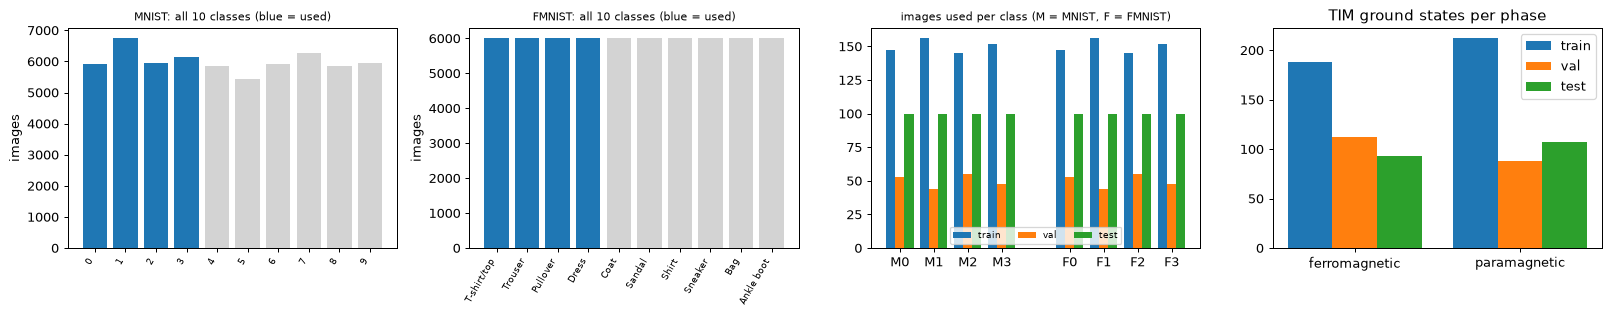

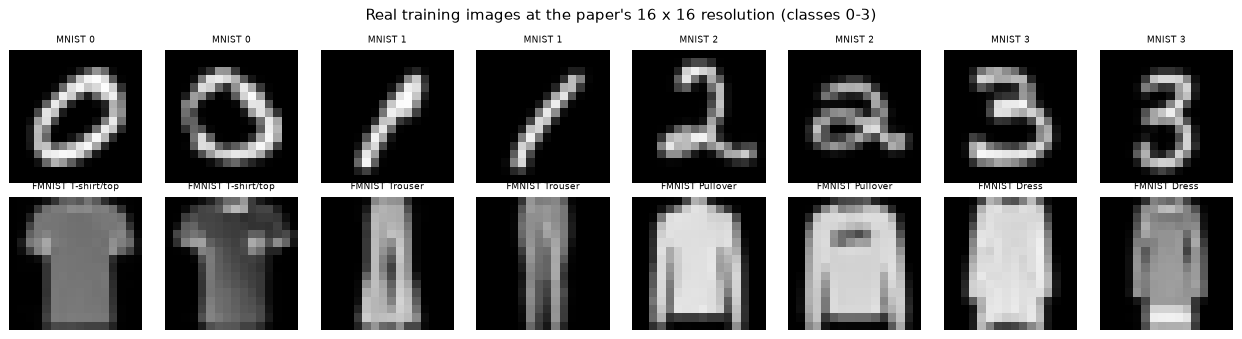

In [5]:
# ---- 1. shapes, feature names, original label values and class counts -------------------------------------------------------------
FEATURE_NAMES_16 = [f"pixel_r{r}_c{c}" for r in range(IMG) for c in range(IMG)]
print(f"feature names (16 x 16 images, flattened): {len(FEATURE_NAMES_16)} features, {FEATURE_NAMES_16[0]} ... {FEATURE_NAMES_16[-1]}")
print("feature names (8 x 8 MNIST images): 64 features, pixel_r0_c0 ... pixel_r7_c7\n")

rows = []
for nm, p in POOLS.items():
    for split in ["tr", "va", "te"]:
        rows.append(dict(dataset=nm, split={"tr": "train", "va": "validation", "te": "test"}[split], shape_16x16=str(p[f"X16_{split}"].shape),
                         shape_8x8=str(p[f"X8_{split}"].shape), labels=np.unique(p[f"y_{split}"]).tolist(),
                         class_counts=np.bincount(p[f"y_{split}"], minlength=4).tolist()))
for split, nm in [("tr", "train"), ("va", "validation"), ("te", "test")]:
    X, y, h = TIM[split]
    rows.append(dict(dataset="TIM (4 qubits)", split=nm, shape_16x16=str(X.shape), shape_8x8="-", labels=np.unique(y).tolist(),
                     class_counts=np.bincount(y, minlength=2).tolist()))
display(pd.DataFrame(rows))
for nm, p in POOLS.items():
    print(f"{nm} original label values (all 10 classes) - counts in the complete official splits:")
    print("  train:", dict(zip(CLASS_NAMES[nm], p["counts_train"].tolist())))
    print("  test :", dict(zip(CLASS_NAMES[nm], p["counts_test"].tolist())))
print("\nTIM labels: 0 = ferromagnetic (h < 1), 1 = paramagnetic (h >= 1); the 16 features are the real amplitudes of the 4-qubit ground state.")

# ---- 2. bar charts of the real class distributions ----------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, nm in zip(ax[:2], POOLS):
    p = POOLS[nm]
    a.bar(range(10), p["counts_train"], color=["tab:blue" if c < 4 else "lightgrey" for c in range(10)])
    a.set_xticks(range(10)); a.set_xticklabels(CLASS_NAMES[nm], rotation=60, ha="right", fontsize=7)
    a.set_title(f"{nm}: all 10 classes (blue = used)", fontsize=9); a.set_ylabel("images")
width = 0.27
for j, nm in enumerate(POOLS):
    p = POOLS[nm]
    cnt = np.array([np.bincount(p[f"y_{s}"], minlength=4) for s in ["tr", "va", "te"]])
    for si, s in enumerate(["train", "val", "test"]):
        ax[2].bar(np.arange(4) + (si - 1) * width + (0 if j == 0 else 5), cnt[si], width, label=f"{s}" if j == 0 else None, color=f"C{si}")
ax[2].set_xticks(list(range(4)) + list(range(5, 9))); ax[2].set_xticklabels([f"M{c}" for c in range(4)] + [f"F{c}" for c in range(4)])
ax[2].set_title("images used per class (M = MNIST, F = FMNIST)", fontsize=9); ax[2].legend(ncol=3, fontsize=7, loc="lower center")
for si, s in enumerate(["tr", "va", "te"]):
    ax[3].bar(np.arange(2) + (si - 1) * width, np.bincount(TIM[s][1], minlength=2), width, label=["train", "val", "test"][si])
ax[3].set_xticks([0, 1]); ax[3].set_xticklabels(["ferromagnetic", "paramagnetic"]); ax[3].set_title("TIM ground states per phase"); ax[3].legend()
plt.tight_layout(); plt.show()

# ---- 3. what the inputs look like: real images --------------------------------------------------------------------------------------
fig, ax = plt.subplots(2, 8, figsize=(14, 3.8))
for r, nm in enumerate(POOLS):
    p = POOLS[nm]
    for c in range(4):
        i = np.where(p["y_tr"] == c)[0][:2]
        for q in range(2):
            ax[r, 2 * c + q].imshow(p["X16_tr"][i[q]], cmap="gray", vmin=0, vmax=1); ax[r, 2 * c + q].axis("off")
            ax[r, 2 * c + q].set_title(f"{nm} {CLASS_NAMES[nm][c]}", fontsize=7)
plt.suptitle("Real training images at the paper's 16 x 16 resolution (classes 0-3)"); plt.tight_layout(); plt.show()

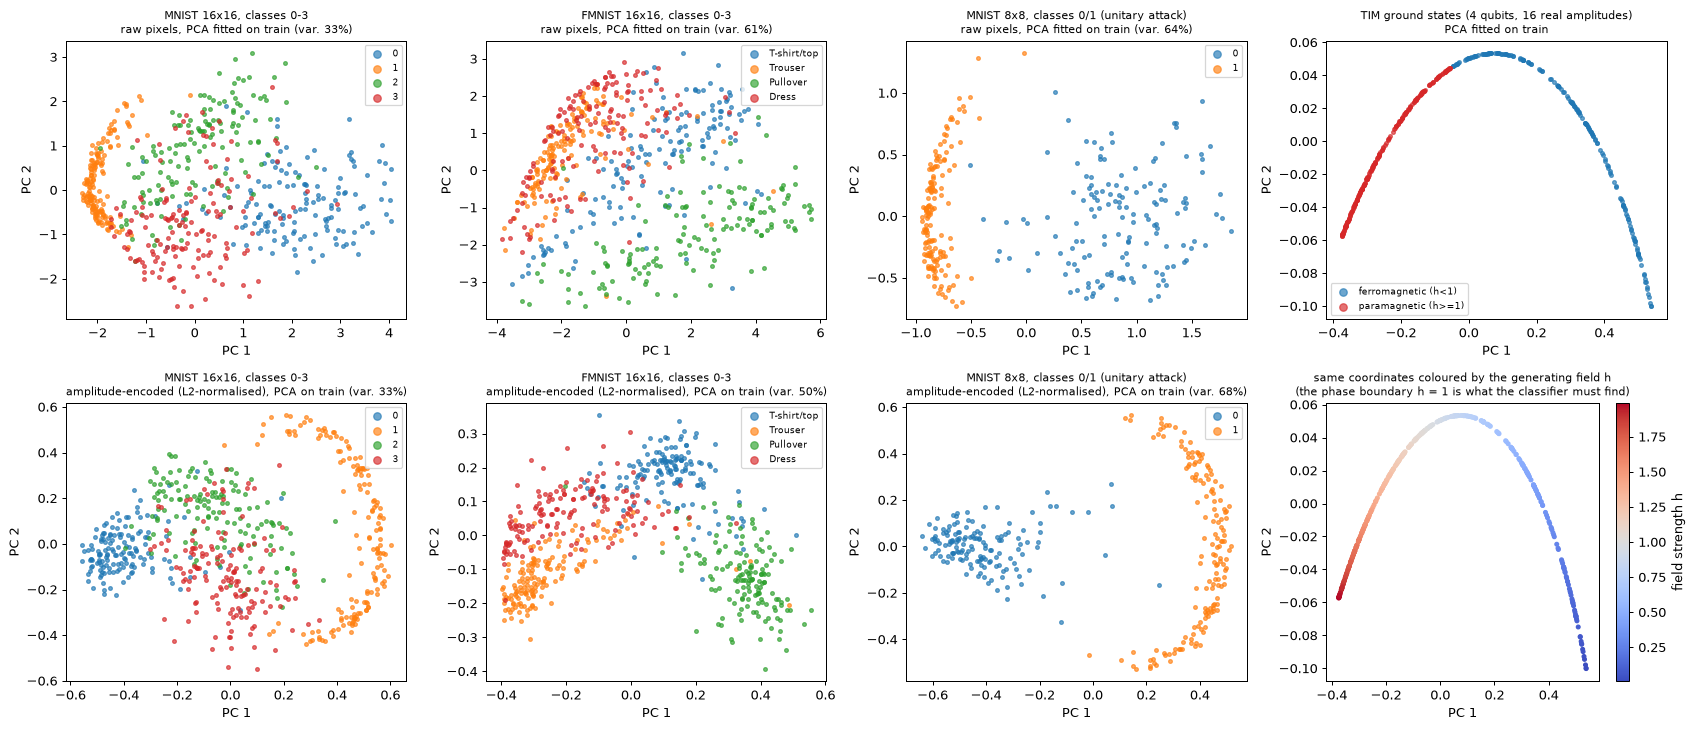

Every dot is a real image (MNIST / Fashion-MNIST) or an exactly diagonalised Ising ground state; colours are ground-truth labels.


In [6]:
# 2-D scatter of REAL observations coloured by their ground-truth label.
# Row 1: raw PCA coordinates of the flattened pixels (PCA fitted on the training split only).
# Row 2: the same PCA fitted on the amplitude-encoded vectors (pixels divided by their L2 norm) - this is what the quantum circuit actually receives.
#        (The classifiers use amplitude encoding, so the [0, pi] angle scaling of the angle-encoding notebooks does not apply.)
fig, ax = plt.subplots(2, 4, figsize=(19, 8.2))
def scatter_panel(a, Z, y, names, title, cmap="tab10"):
    for c in np.unique(y):
        m = y == c
        a.scatter(Z[m, 0], Z[m, 1], s=9, alpha=0.65, label=names[c], color=plt.get_cmap(cmap)(c % 10))
    a.set_title(title, fontsize=9); a.set_xlabel("PC 1"); a.set_ylabel("PC 2"); a.legend(fontsize=7, markerscale=2)

panels = []
for nm in POOLS:
    p = POOLS[nm]
    panels.append((f"{nm} 16x16, classes 0-3", p["X16_tr"].reshape(len(p["y_tr"]), -1), p["y_tr"], CLASS_NAMES[nm]))
p = POOLS["MNIST"]; m01 = p["y_tr"] < 2
panels.append(("MNIST 8x8, classes 0/1 (unitary attack)", p["X8_tr"][m01].reshape(m01.sum(), -1), p["y_tr"][m01], CLASS_NAMES["MNIST"]))
for j, (title, X, y, names) in enumerate(panels):
    pca = PCA(n_components=2, random_state=SEED).fit(X)
    scatter_panel(ax[0, j], pca.transform(X), y, names, f"{title}\nraw pixels, PCA fitted on train (var. {pca.explained_variance_ratio_.sum():.0%})")
    Xa = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
    pca2 = PCA(n_components=2, random_state=SEED).fit(Xa)
    scatter_panel(ax[1, j], pca2.transform(Xa), y, names, f"{title}\namplitude-encoded (L2-normalised), PCA on train (var. {pca2.explained_variance_ratio_.sum():.0%})")

Xt, yt, ht = TIM["tr"]
pca = PCA(n_components=2, random_state=SEED).fit(Xt)
for c_, nm_, col_ in [(0, "ferromagnetic (h<1)", "tab:blue"), (1, "paramagnetic (h>=1)", "tab:red")]:
    Z_ = pca.transform(Xt[yt == c_]); ax[0, 3].scatter(Z_[:, 0], Z_[:, 1], s=9, alpha=0.65, color=col_, label=nm_)
ax[0, 3].set_title("TIM ground states (4 qubits, 16 real amplitudes)\nPCA fitted on train", fontsize=9); ax[0, 3].set_xlabel("PC 1"); ax[0, 3].set_ylabel("PC 2"); ax[0, 3].legend(fontsize=7, markerscale=2)
sc = ax[1, 3].scatter(*pca.transform(Xt).T, c=ht, s=9, cmap="coolwarm"); plt.colorbar(sc, ax=ax[1, 3], label="field strength h")
ax[1, 3].set_title("same coordinates coloured by the generating field h\n(the phase boundary h = 1 is what the classifier must find)", fontsize=9)
ax[1, 3].set_xlabel("PC 1"); ax[1, 3].set_ylabel("PC 2")
plt.tight_layout(); plt.show()
print("Every dot is a real image (MNIST / Fashion-MNIST) or an exactly diagonalised Ising ground state; colours are ground-truth labels.")

## 2. An exact simulator, verified against PennyLane

All attacks need thousands of forward and backward passes through circuits with 10-60 layers on 5-10 qubits. PennyLane's QNode is too slow for that on a CPU, so the notebook uses a small batched
PyTorch state-vector simulator for `StronglyEntanglingLayers` (exact, noiseless, complex64). Two facts make the attacks cheap:

* **Lemma 1 of the paper.** Applying the PQC to the state |x>|0..0> and measuring the ancillas is linear in |x>: with `Wm[j, t*K + c] = <t, c| U |j, 0>` the class probabilities of any input vector phi are
  `P(c) = sum_t |(phi @ Wm)[t*K + c]|^2`, i.e. the quadratic form x^T M_c x of the paper. `qmatrix` computes `Wm` once per trained circuit.
* **Gradients** with respect to the input (needed by every attack) come from PyTorch autograd through this matrix product, exactly (the paper says the same: "straightforward once the parameters of Q are known").

The next cell then **asserts that the simulator equals the real PennyLane QNodes** (amplitude-encoded classifier with 1 and 2 ancillas, and the QuGAP-U pipeline generator + classifier) in outputs and gradients.

In [7]:
# ----------------------------------------------------------------------------------------------------------------
# An exact, batched state-vector simulator for  qml.StronglyEntanglingLayers  written in plain PyTorch.
# Why: attacks need thousands of forward/backward passes through 10-60 layer circuits; PennyLane's QNode needs seconds per pass
# on a CPU, this simulator milliseconds. It is exact (no shots, no approximation) and is checked against the real PennyLane QNodes
# in the next cells (outputs, input gradients and the full attacked pipeline). Wire 0 is the most significant bit (PennyLane convention).
# ----------------------------------------------------------------------------------------------------------------
CDT = torch.complex64

def rot_mats(a):
    """Matrices of qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) for angles a[..., 3] -> [..., 2, 2]."""
    phi, th, om = a[..., 0], a[..., 1], a[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    e = lambda z: torch.polar(torch.ones_like(z), z)             # exp(i z)
    m00 = e(-(phi + om) / 2) * c; m01 = -e((phi - om) / 2) * s
    m10 = e(-(phi - om) / 2) * s; m11 = e((phi + om) / 2) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def kron_n(M):
    """Kronecker product of the 2x2 matrices M[..., j, :, :] over j."""
    out = M[..., 0, :, :]
    for j in range(1, M.shape[-3]):
        n = out.shape[-1]
        out = torch.einsum("...ij,...kl->...ikjl", out, M[..., j, :, :]).reshape(*out.shape[:-2], 2 * n, 2 * n)
    return out

_SRC = {}
def cnot_src(n, l):
    """Index map of the CNOT ring of layer l: CNOT(i, (i + r) % n) for i = 0..n-1 with r = l % (n-1) + 1 (PennyLane's default ranges)."""
    key = (n, l % (n - 1))
    if key not in _SRC:
        r = key[1] + 1
        idx = np.arange(2 ** n); cur = idx.copy()
        for i in range(n):
            t = (i + r) % n
            cbit = (idx >> (n - 1 - i)) & 1
            cur = cur[idx ^ (cbit << (n - 1 - t))]
        _SRC[key] = torch.as_tensor(cur, dtype=torch.long)
    return _SRC[key]

def sel_apply(state, W, entangle=True):
    """Apply L StronglyEntanglingLayers with angles W[L, n, 3] to a batch of states [B, 2^n] (complex)."""
    L, n, _ = W.shape; h = n // 2
    B = state.shape[0]
    U = rot_mats(W)                                              # [L, n, 2, 2]
    UA = kron_n(U[:, :h]); UB = kron_n(U[:, h:]).transpose(-1, -2)   # rotations of the first h wires / of the others, one matrix per layer
    s = state.to(CDT).reshape(B, 2 ** h, 2 ** (n - h))
    for l in range(L):
        s = UA[l] @ s @ UB[l]
        if entangle:
            s = s.reshape(B, 2 ** n)[:, cnot_src(n, l)].reshape(B, 2 ** h, 2 ** (n - h))
    return s.reshape(B, 2 ** n)

def qmatrix(W, d, K):
    """Rows of the classifier unitary restricted to inputs |j>|0..0>:  Wm[j, t*K + c] = <t, c| U |j, 0>  (shape d x d*K).
    With it, an input state phi (any complex vector of length d) is classified by  P(c) = sum_t |(phi @ Wm)[t*K + c]|^2  (Lemma 1 of the paper)."""
    st = torch.zeros(d, d * K, dtype=CDT)
    st[torch.arange(d), torch.arange(d) * K] = 1
    return sel_apply(st, W)

def probs_from_wm(phi, Wm, d, K, k):
    """Class probabilities (ancilla marginal) for input states phi[B, d] using the precomputed matrix Wm; keeps the first k ancilla values."""
    amp = phi.to(CDT) @ Wm
    p = (amp.real ** 2 + amp.imag ** 2).reshape(-1, d, K).sum(1)
    return p[:, :k]

def probs_direct(phi, W, d, K, k):
    """Same probabilities by running the whole circuit on |phi>|0..0> (what the QNode does); used for training."""
    B = phi.shape[0]
    st = torch.zeros(B, d * K, dtype=CDT); st[:, ::K] = phi.to(CDT)
    out = sel_apply(st, W)
    p = (out.real ** 2 + out.imag ** 2).reshape(B, d, K).sum(1)
    return p[:, :k]

def amp_norm(x):
    """Amplitude encoding of a batch of images: flatten and L2-normalise (this is what qml.AmplitudeEmbedding(normalize=True) does)."""
    x = x.reshape(x.shape[0], -1)
    return x / (x.norm(dim=1, keepdim=True) + 1e-8)

def nll(p, y):
    return -torch.log(p.gather(1, y[:, None]) + 1e-6).mean()          # cross-entropy on the measured class probabilities

# ---- generator ansatz of QuGAP-U: L layers of [Rot on every qubit, IsingZZ on the ring (i, i+1 mod n)]; all angles 0 = identity ----
_ZZ = {}
def zz_table(n):
    if n not in _ZZ:
        idx = torch.arange(2 ** n)
        Z = torch.stack([1 - 2 * ((idx >> (n - 1 - q)) & 1).float() for q in range(n)])
        _ZZ[n] = torch.stack([Z[i] * Z[(i + 1) % n] for i in range(n)])          # [n, 2^n]: z_i * z_{i+1} of every basis state
    return _ZZ[n]

def gen_apply(state, W):
    """Apply the generator with angles W[L, n, 4] (3 for Rot, 1 for IsingZZ(i, i+1)) to a batch of states [B, 2^n]. IsingZZ(phi) = exp(-i phi/2 Z Z) is diagonal."""
    L, n, _ = W.shape; h = n // 2
    B = state.shape[0]
    U = rot_mats(W[..., :3]); UA = kron_n(U[:, :h]); UB = kron_n(U[:, h:]).transpose(-1, -2)
    ph = torch.exp(torch.complex(torch.zeros(L, 2 ** n), -0.5 * (W[..., 3] @ zz_table(n)))).to(CDT)
    s = state.to(CDT).reshape(B, 2 ** h, 2 ** (n - h))
    for l in range(L):
        s = UA[l] @ s @ UB[l]
        s = (s.reshape(B, 2 ** n) * ph[l]).reshape(B, 2 ** h, 2 ** (n - h))
    return s.reshape(B, 2 ** n)

In [8]:
# ---- the REAL PennyLane QNodes of the paper's pipeline (used for verification, for the final evaluation and for the circuit drawings) ----
def make_clf_qnode(n_data, n_anc):
    """Classifier of Assumptions 3-4: amplitude-embed the data on n_data qubits, apply a PQC (StronglyEntanglingLayers) on all
    n_data + n_anc qubits, read the class from the ancilla qubits (class c = ancilla bit string c)."""
    n = n_data + n_anc
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def clf(x, W):
        qml.AmplitudeEmbedding(x, wires=range(n_data), normalize=True)
        qml.StronglyEntanglingLayers(W, wires=range(n))
        return qml.probs(wires=range(n_data, n))
    return clf

class RotZZLayers(qml.operation.Operation):
    """The QuGAP-U generator ansatz as one PennyLane operation: for each layer, Rot on every qubit, then IsingZZ on the ring (i, i+1 mod n).
    weights[L, n, 4] = (phi, theta, omega, zz-angle). Zero weights give the identity. Drawn as one box at template level, as gates at device level."""
    ndim_params = (3,)
    def __init__(self, weights, wires, id=None):
        super().__init__(weights, wires=wires, id=id)
    @staticmethod
    def compute_decomposition(weights, wires):
        n = len(wires); ops = []
        for l in range(weights.shape[0]):
            for i in range(n):
                ops.append(qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=wires[i]))
            for i in range(n):
                ops.append(qml.IsingZZ(weights[l, i, 3], wires=[wires[i], wires[(i + 1) % n]]))
        return ops

def make_attack_qnode(n_data, n_anc):
    """QuGAP-U pipeline: quantum data |psi> -> PQC generator U_G on the data qubits -> classifier PQC -> ancilla read-out."""
    n = n_data + n_anc
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def attack(psi, Wg, Wc):
        qml.StatePrep(psi, wires=range(n_data), normalize=True)
        RotZZLayers(Wg, wires=range(n_data))                              # the generator G_Q (acts on the data qubits only)
        qml.StronglyEntanglingLayers(Wc, wires=range(n))                 # the trained classifier Q
        return qml.probs(wires=range(n_data, n))
    return attack

# ---- equivalence checks: our simulator == PennyLane (double precision), outputs and gradients -----------------------------------------
g = torch.Generator().manual_seed(SEED)
print("(a) amplitude-encoded classifier, PennyLane QNode vs our simulator")
for (n_data, n_anc, k, depth) in [(8, 1, 2, 10), (8, 2, 4, 10), (8, 1, 2, 20)]:
    d, K = 2 ** n_data, 2 ** n_anc
    Wr = Q_INIT_STD * torch.randn(depth, n_data + n_anc, 3, generator=g)
    xr = torch.rand(3, d, generator=g)
    clf = make_clf_qnode(n_data, n_anc)
    x1 = xr.double().requires_grad_(True); ref = clf(x1, Wr.double()); ref[:, 1].sum().backward()
    x2 = xr.clone().requires_grad_(True); ours = probs_direct(amp_norm(x2), Wr, d, K, K); ours[:, 1].sum().backward()
    x3 = xr.clone().requires_grad_(True); via = probs_from_wm(amp_norm(x3), qmatrix(Wr, d, K), d, K, K); via[:, 1].sum().backward()
    e_out, e_grad, e_wm = (ref - ours).abs().max().item(), (x1.grad - x2.grad).abs().max().item(), (ref - via).abs().max().item()
    print(f"  {n_data}+{n_anc} qubits, depth {depth:2d}: max |p_PL - p_ours| = {e_out:.1e}, input-gradient diff = {e_grad:.1e}, "
          f"Lemma-1 matrix form (phi @ Wm) diff = {e_wm:.1e}")
    assert e_out < 1e-5 and e_wm < 1e-5 and e_grad < 1e-4, "simulator disagrees with PennyLane"

print("(b) QuGAP-U pipeline (generator + classifier), PennyLane QNode vs our simulator")
for (n_data, gl, cl) in [(TIM_QUBITS, 30, 10), (M8_QUBITS, 20, 10)]:
    d, n_anc = 2 ** n_data, 1
    Wg = 0.3 * torch.randn(gl, n_data, 4, generator=g); Wc = Q_INIT_STD * torch.randn(cl, n_data + 1, 3, generator=g)
    psi = torch.rand(3, d, generator=g); psi = psi / psi.norm(dim=1, keepdim=True)
    att = make_attack_qnode(n_data, n_anc)
    Wg1 = Wg.double().requires_grad_(True); ref = att(psi.double(), Wg1, Wc.double()); ref[:, 0].sum().backward()
    Wg2 = Wg.clone().requires_grad_(True)
    ours = probs_from_wm(gen_apply(psi.to(CDT), Wg2), qmatrix(Wc, d, 2), d, 2, 2); ours[:, 0].sum().backward()
    e_out, e_grad = (ref - ours).abs().max().item(), (Wg1.grad - Wg2.grad).abs().max().item()
    print(f"  {n_data} data qubits, generator {gl} layers, classifier {cl} layers: max |p_PL - p_ours| = {e_out:.1e}, generator-gradient diff = {e_grad:.1e}")
    assert e_out < 1e-5 and e_grad < 1e-4, "simulator disagrees with PennyLane"
print("All simulator checks passed: the exact simulator is the PennyLane circuit (to single-precision round-off).")

(a) amplitude-encoded classifier, PennyLane QNode vs our simulator


  8+1 qubits, depth 10: max |p_PL - p_ours| = 4.3e-07, input-gradient diff = 3.6e-08, Lemma-1 matrix form (phi @ Wm) diff = 3.7e-07


  8+2 qubits, depth 10: max |p_PL - p_ours| = 3.8e-07, input-gradient diff = 5.5e-08, Lemma-1 matrix form (phi @ Wm) diff = 3.8e-07


  8+1 qubits, depth 20: max |p_PL - p_ours| = 1.1e-06, input-gradient diff = 6.9e-08, Lemma-1 matrix form (phi @ Wm) diff = 1.0e-06
(b) QuGAP-U pipeline (generator + classifier), PennyLane QNode vs our simulator


  4 data qubits, generator 30 layers, classifier 10 layers: max |p_PL - p_ours| = 5.0e-07, generator-gradient diff = 8.7e-07


  6 data qubits, generator 20 layers, classifier 10 layers: max |p_PL - p_ours| = 2.3e-07, generator-gradient diff = 2.9e-07
All simulator checks passed: the exact simulator is the PennyLane circuit (to single-precision round-off).


## 3. Training the quantum classifiers and the classical baselines

For each of the four experimental settings of Fig. 2 (MNIST / FMNIST, binary / 4-class) the notebook trains PQC classifiers of every depth in `Q_DEPTHS`, a classical CNN, a random forest and an SVC(rbf), all on
the same 256 pixels. The quantum models see the pixels amplitude-encoded (divided by their L2 norm); the CNN, the forest and the SVC see the raw pixels in [0, 1].
Only correctly classified test images are attacked later (the paper's metric), so a classifier's clean accuracy matters for the size of the attacked set.

In [9]:
D_IMG = 8                      # 16 x 16 = 256 = 2^8 amplitudes -> 8 data qubits (paper)

def train_q(X, y, n_data, n_anc, k, depth, seed, steps=Q_STEPS):
    """Train a PQC classifier (StronglyEntanglingLayers) with Adam on the cross-entropy of the measured class probabilities."""
    d, K = 2 ** n_data, 2 ** n_anc
    gen = torch.Generator().manual_seed(seed)
    W = (Q_INIT_STD * torch.randn(depth, n_data + n_anc, 3, generator=gen)).requires_grad_()   # CHOICE: normal init of all angles
    opt = torch.optim.Adam([W], lr=Q_LR)
    Xt, yt = torch.as_tensor(X, dtype=torch.float32), torch.as_tensor(y)
    for s in range(steps):
        idx = torch.randint(0, len(yt), (Q_BATCH,), generator=gen)
        loss = nll(probs_direct(amp_norm(Xt[idx]), W, d, K, k), yt[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    return W.detach()

class CNN(nn.Module):
    """The classical convolutional baseline of the paper's Fig. 2 (architecture not given: two 3x3 conv blocks + linear layer)."""
    def __init__(self, k):
        super().__init__()
        self.c1 = nn.Conv2d(1, 8, 3, padding=1); self.c2 = nn.Conv2d(8, 16, 3, padding=1); self.fc = nn.Linear(16 * 4 * 4, k)
    def forward(self, x):
        x = x.reshape(-1, 1, IMG, IMG)
        x = F.max_pool2d(F.relu(self.c1(x)), 2); x = F.max_pool2d(F.relu(self.c2(x)), 2)
        return self.fc(x.flatten(1))

def train_cnn(X, y, k, seed, epochs=CNN_EPOCHS):
    torch.manual_seed(seed)
    net = CNN(k); opt = torch.optim.Adam(net.parameters(), lr=2e-3)
    Xt, yt = torch.as_tensor(X.reshape(len(X), -1)), torch.as_tensor(y)
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        perm = torch.randperm(len(yt), generator=g)
        for i in range(0, len(yt), 64):
            b = perm[i:i + 64]
            loss = F.cross_entropy(net(Xt[b]), yt[b])
            opt.zero_grad(); loss.backward(); opt.step()
    return net.eval()

# ---- build the four experimental settings of the paper's Fig. 2 and train every model on each ----------------------------------------
SETTINGS, MODELS = {}, {}
rows = []
for ds in ["MNIST", "FMNIST"]:
    p = POOLS[ds]
    for k in [2, 4]:
        mk = {s: p[f"y_{s}"] < k for s in ["tr", "va", "te"]}
        S = {s: (p[f"X16_{s}"][mk[s]].reshape(mk[s].sum(), -1).astype(np.float32), p[f"y_{s}"][mk[s]].astype(np.int64)) for s in ["tr", "va", "te"]}
        SETTINGS[(ds, k)] = S
        n_anc = 1 if k == 2 else 2; d, K = 2 ** D_IMG, 2 ** n_anc
        M = {}
        for depth in Q_DEPTHS:
            t0 = time.time()
            W = train_q(S["tr"][0], S["tr"][1], D_IMG, n_anc, k, depth, SEED)
            Wm = qmatrix(W, d, K)
            f = (lambda Wm_, d_, K_, k_: (lambda x: probs_from_wm(amp_norm(x), Wm_, d_, K_, k_)))(Wm, d, K, k)
            M[f"Q{depth}"] = dict(prob=f, W=W, Wm=Wm, kind="quantum", n_anc=n_anc, k=k, secs=time.time() - t0)
        t0 = time.time()
        net = train_cnn(S["tr"][0], S["tr"][1], k, SEED)
        M["CNN"] = dict(prob=(lambda net_: (lambda x: F.softmax(net_(x), 1)))(net), net=net, kind="classical", k=k, secs=time.time() - t0)
        MODELS[(ds, k)] = M
        for nm, m in M.items():
            with torch.no_grad():
                acc = {s: float((m["prob"](torch.as_tensor(S[s][0])).argmax(1).numpy() == S[s][1]).mean()) for s in ["tr", "va", "te"]}
            m["acc"] = acc
            rows.append(dict(setting=f"{ds} {k}-class", model=nm, train_acc=acc["tr"], val_acc=acc["va"], test_acc=acc["te"], train_secs=round(m["secs"], 1)))
        # scikit-learn baselines on the same 256 pixels (they see raw pixels, the quantum model sees the same pixels L2-normalised)
        for nm, clf in [("RandomForest", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2)), ("SVC(rbf)", SVC(kernel="rbf", random_state=SEED))]:
            t0 = time.time(); clf.fit(*S["tr"])
            M[nm] = dict(clf=clf, kind="sklearn", k=k)
            acc = {s: float((clf.predict(S[s][0]) == S[s][1]).mean()) for s in ["tr", "va", "te"]}
            M[nm]["acc"] = acc
            rows.append(dict(setting=f"{ds} {k}-class", model=nm, train_acc=acc["tr"], val_acc=acc["va"], test_acc=acc["te"], train_secs=round(time.time() - t0, 1)))
CLEAN = pd.DataFrame(rows)
display(CLEAN.round(3))

,setting,model,train_acc,val_acc,test_acc,train_secs
0,MNIST 2-class,Q10,0.993,0.979,1.000,33.2
1,MNIST 2-class,Q20,0.997,0.990,1.000,17.3
2,MNIST 2-class,CNN,0.980,0.979,1.000,0.7
3,MNIST 2-class,RandomForest,1.000,1.000,1.000,2.4
4,MNIST 2-class,SVC(rbf),1.000,1.000,1.000,0.0
5,MNIST 4-class,Q10,0.860,0.855,0.862,15.2
6,MNIST 4-class,Q20,0.908,0.920,0.900,33.3
7,MNIST 4-class,CNN,0.963,0.935,0.960,1.4
8,MNIST 4-class,RandomForest,1.000,0.965,0.988,2.1
9,MNIST 4-class,SVC(rbf),0.993,0.965,0.990,0.1


## 4. QuGAP-A: additive universal perturbations from a classical generator

`train_uap_generator` implements the box of the paper's Fig. 1: a fixed random vector z goes through a classical generator G, the output is squashed and scaled to ||delta||_inf <= epsilon (`epsilon * tanh`),
added to the image, clipped to [0, 1] and passed through the quantum classifier; G is trained by gradient ascent on the cross-entropy. The perturbation is then frozen and evaluated on the
*test* images that the clean classifier gets right. For every attacked model we also evaluate the same perturbation on the other models (the transfer experiment of the next section).
Two controls are added that the paper does not have: **per-sample PGD** (a different perturbation for every image: the upper reference for any universal attack) and a **random-sign universal perturbation**
(no optimisation: what the attack gains from being optimised).

In [10]:
def predict_labels(m, X):
    """Predicted labels of any model (quantum / CNN / scikit-learn) for an array of flattened images X[N, 256] in [0, 1]."""
    if m["kind"] == "sklearn":
        return m["clf"].predict(np.asarray(X))
    with torch.no_grad():
        return m["prob"](torch.as_tensor(np.asarray(X), dtype=torch.float32)).argmax(1).numpy()

def clean_correct(m, X, y):
    ok = predict_labels(m, X) == y
    return X[ok], y[ok]

def apply_uap(X, delta):
    """Additive perturbation followed by clipping to the valid pixel range [0, 1] (paper: 'an additional step of clipping')."""
    return np.clip(X + np.asarray(delta)[None, :], 0.0, 1.0).astype(np.float32)

def mis_rate(m, X, y, delta):
    """Misclassification rate = share of the CORRECTLY classified clean samples that are misclassified after the attack (paper's metric)."""
    Xc, yc = clean_correct(m, X, y)
    return 100.0 * float((predict_labels(m, apply_uap(Xc, delta)) != yc).mean())

def train_uap_generator(m, X, y, eps, seed, steps=GEN_STEPS):
    """QuGAP-A: a classical generator G maps a fixed random vector z to an additive perturbation scaled to ||delta||_inf <= eps.
    G is trained by gradient ascent on the untargeted fooling loss  L_fool = - sum CE(Q(clip(x + delta)), c_x)  through the quantum classifier."""
    Xc, yc = clean_correct(m, X, y)
    Xc, yc = torch.as_tensor(Xc), torch.as_tensor(yc)
    gen = torch.Generator().manual_seed(seed)
    z = torch.randn(1, Z_DIM, generator=gen)
    G = nn.Sequential(nn.Linear(Z_DIM, GEN_HIDDEN), nn.ReLU(), nn.Linear(GEN_HIDDEN, IMG * IMG))
    torch.manual_seed(seed)
    for layer in G:
        if isinstance(layer, nn.Linear): layer.reset_parameters()
    opt = torch.optim.Adam(G.parameters(), lr=GEN_LR)
    best, best_loss = None, 1e9
    for s in range(steps):
        idx = torch.randint(0, len(yc), (min(GEN_BATCH, len(yc)),), generator=gen)
        delta = eps * torch.tanh(G(z))                                   # scaling that enforces the L-infinity budget
        xa = torch.clamp(Xc[idx] + delta, 0.0, 1.0)
        loss = -(-torch.log(m["prob"](xa).gather(1, yc[idx][:, None]) + 1e-6).mean())    # L_fool,untargeted = - CE
        opt.zero_grad(); loss.backward(); opt.step()
    return (eps * torch.tanh(G(z))).detach()[0].numpy()

def per_sample_pgd(m, X, y, eps, steps=PGD_STEPS):
    """Per-sample L-infinity PGD (white box, a different perturbation for every image): the usual non-universal reference attack."""
    Xc, yc = clean_correct(m, X, y)
    x0, yt = torch.as_tensor(Xc), torch.as_tensor(yc)
    xa = x0.clone(); a = 2.5 * eps / steps
    for _ in range(steps):
        xa.requires_grad_(True)
        loss = -torch.log(m["prob"](xa).gather(1, yt[:, None]) + 1e-6).mean()
        g, = torch.autograd.grad(loss, xa)
        xa = torch.clamp(torch.min(torch.max(xa.detach() + a * g.sign(), x0 - eps), x0 + eps), 0, 1)
    return 100.0 * float((predict_labels(m, xa.numpy()) != yc).mean())

def random_uap(m, X, y, eps, seed):
    """Control: a universal perturbation with random signs, delta = eps * sign(noise) (no optimisation)."""
    d = eps * np.sign(np.random.default_rng(seed).standard_normal(IMG * IMG))
    return mis_rate(m, X, y, d)

In [11]:
t0 = time.time()
res_rows, per_rows, DELTAS = [], [], {}
for (ds, k), M in MODELS.items():
    X, y = SETTINGS[(ds, k)]["te"]
    Xtr_, ytr_ = SETTINGS[(ds, k)]["tr"]
    sources = [n for n in M if M[n]["kind"] in ("quantum", "classical")]
    for src in sources:
        for eps in EPS_LIST:
            for run in range(N_RUNS):
                delta = train_uap_generator(M[src], Xtr_, ytr_, eps, seed=SEED + 1000 * run + int(1000 * eps))
                if run == 0: DELTAS[(ds, k, src, eps)] = delta
                for tgt in M:
                    if M[tgt]["kind"] == "sklearn" and run >= 2:       # random forests / SVMs are slow to query: first 2 runs only
                        continue
                    res_rows.append(dict(ds=ds, k=k, source=src, target=tgt, eps=eps, run=run, mis=mis_rate(M[tgt], X, y, delta)))
    for nm in sources:                                                    # per-sample PGD and random-sign controls
        for eps in EPS_LIST:
            per_rows.append(dict(ds=ds, k=k, model=nm, eps=eps, pgd=per_sample_pgd(M[nm], X, y, eps),
                                 rand=float(np.mean([random_uap(M[nm], X, y, eps, s) for s in range(5)]))))
    print(f"[{time.time() - t0:6.0f}s] finished {ds} {k}-class")
RES = pd.DataFrame(res_rows); PER = pd.DataFrame(per_rows)
print(f"{len(RES)} attack evaluations, total {time.time() - t0:.0f} s")

[   315s] finished MNIST 2-class


[   836s] finished MNIST 4-class


[  1302s] finished FMNIST 2-class


[  2043s] finished FMNIST 4-class
780 attack evaluations, total 2043 s


### Re-drawing Fig. 2: misclassification versus perturbation budget

The solid lines are QuGAP-A trained against the model on the curve (mean +- std over runs). The paper's plot shows the same quantity for the quantum depths and the CNN in four panels.
Its text makes two statements about the curves: they rise with epsilon, and they plateau near (k-1)/k, the rate obtained if every input were classified as one fixed class.

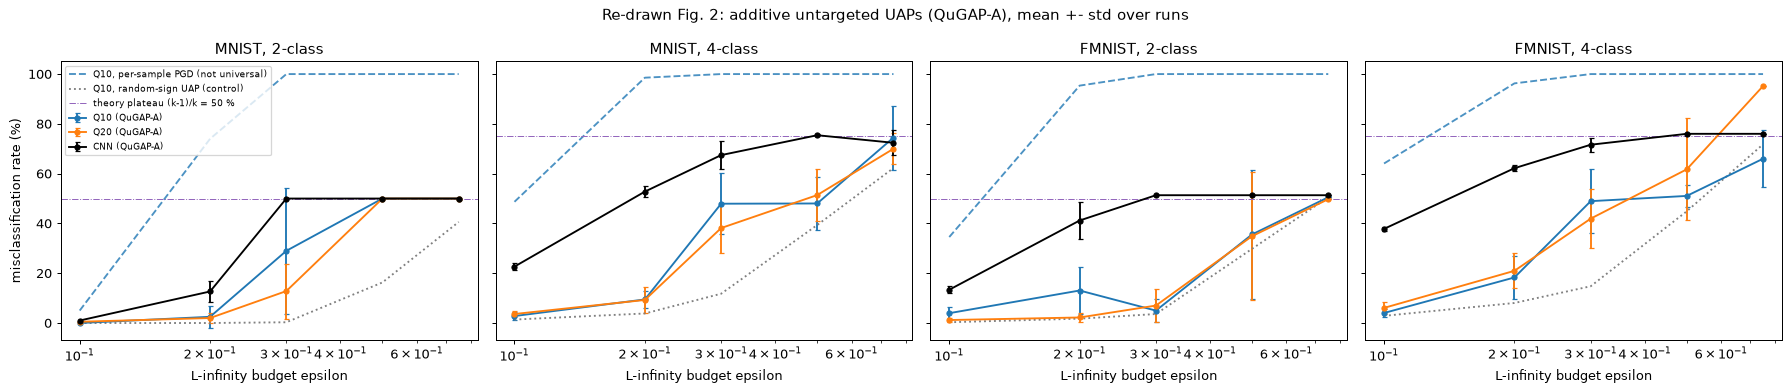

Misclassification (%) at the largest budget epsilon = 0.75 (mean over 3 runs):


target     CNN   Q10   Q20
ds     k                  
FMNIST 2  51.3  50.5  49.7
       4  76.0  66.0  95.2
MNIST  2  50.0  50.0  50.0
       4  72.4  74.5  70.0

In [12]:
# ---- Fig. 2 of the paper: misclassification rate of white-box QuGAP-A (generator trained against the model that is attacked) ----------
WB = RES[RES.source == RES.target]
agg = WB.groupby(["ds", "k", "target", "eps"]).mis.agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(1, 4, figsize=(20, 4.4), sharey=True)
colors = {n: c for n, c in zip([f"Q{d}" for d in [10, 20, 40, 60]] + ["CNN"], ["tab:blue", "tab:orange", "tab:green", "tab:red", "k"])}
for a, ((ds, k), M) in zip(ax, MODELS.items()):
    for nm in [n for n in M if M[n]["kind"] != "sklearn"]:
        s = agg[(agg.ds == ds) & (agg.k == k) & (agg.target == nm)].sort_values("eps")
        a.errorbar(s.eps, s["mean"], yerr=s["std"].fillna(0), marker="o", ms=4, capsize=2, color=colors[nm], label=f"{nm} (QuGAP-A)")
    pp = PER[(PER.ds == ds) & (PER.k == k) & (PER.model == "Q10")].sort_values("eps")
    a.plot(pp.eps, pp.pgd, "--", color="tab:blue", alpha=0.8, label="Q10, per-sample PGD (not universal)")
    a.plot(pp.eps, pp.rand, ":", color="grey", label="Q10, random-sign UAP (control)")
    a.axhline(100 * (k - 1) / k, color="tab:purple", lw=0.8, ls="-.", label=f"theory plateau (k-1)/k = {100 * (k - 1) / k:.0f} %")
    a.set_title(f"{ds}, {k}-class"); a.set_xlabel("L-infinity budget epsilon"); a.set_xscale("log")
ax[0].set_ylabel("misclassification rate (%)"); ax[0].legend(fontsize=7, loc="upper left")
plt.suptitle("Re-drawn Fig. 2: additive untargeted UAPs (QuGAP-A), mean +- std over runs"); plt.tight_layout(); plt.show()

tab = agg[agg.eps == max(EPS_LIST)].pivot_table(index=["ds", "k"], columns="target", values="mean")
print(f"Misclassification (%) at the largest budget epsilon = {max(EPS_LIST)} (mean over {N_RUNS} runs):")
display(tab.round(1))

### Transfer: the same UAP against other models

The paper notes that the naive alternative, crafting the UAP for a classical classifier and transferring it, "does not transfer well" (numbers are in the supplement). The matrix below checks this
and also answers a different question: **how does a classical model fare under the same UAP?** The CNN, the random forest and the SVC are attacked with the perturbations generated against the quantum models, and the quantum
models with the perturbations generated against the CNN.

In [13]:
# ---- Transfer: the same UAP applied to other models (quantum depths, the classical CNN, RandomForest, SVC) --------------------------
EPS_T = EPS_LIST[min(3, len(EPS_LIST) - 1)]       # a mid-range budget (0.2 for the default grid)
sub = RES[RES.eps == EPS_T]
print(f"Mean misclassification (%) when the UAP generated against 'source' (rows) is applied to 'target' (columns); epsilon = {EPS_T}; diagonal = white box")
for (ds, k) in MODELS:
    t = sub[(sub.ds == ds) & (sub.k == k)].pivot_table(index="source", columns="target", values="mis", aggfunc="mean")
    cols = [c for c in ["Q10", "Q20", "Q40", "Q60", "CNN", "RandomForest", "SVC(rbf)"] if c in t.columns]
    print(f"\n{ds}, {k}-class"); display(t.reindex(columns=cols).round(1))

def share(df, sources, targets, same=False):
    m = df[df.source.isin(sources) & df.target.isin(targets) & ((df.source == df.target) == same)]
    return float(m.mis.mean()) if len(m) else float("nan")
qs = [n for n in ["Q10", "Q20", "Q40", "Q60"] if n in RES.source.unique()]
TRANSFER = dict(
    white_box_quantum=share(sub, qs, qs, same=True),
    quantum_to_other_quantum_depth=share(sub, qs, qs, same=False),
    cnn_to_quantum=share(sub, ["CNN"], qs),
    quantum_to_cnn=share(sub, qs, ["CNN"]),
    cnn_white_box=share(sub, ["CNN"], ["CNN"], same=True),
    quantum_to_forest_svc=share(sub, qs, ["RandomForest", "SVC(rbf)"]),
)
print("\nSummary over all four settings:", {k_: round(v, 1) for k_, v in TRANSFER.items()})

Mean misclassification (%) when the UAP generated against 'source' (rows) is applied to 'target' (columns); epsilon = 0.5; diagonal = white box

MNIST, 2-class


target,Q10,Q20,CNN,RandomForest,SVC(rbf)
source,,,,,
CNN,50.0,50.0,50.0,49.2,50.0
Q10,50.0,40.7,50.0,50.0,50.0
Q20,46.5,50.0,50.0,50.0,50.0



MNIST, 4-class

target,Q10,Q20,CNN,RandomForest,SVC(rbf)
source,,,,,
CNN,70.0,56.9,75.4,74.2,75.1
Q10,48.0,50.5,41.3,56.3,58.2
Q20,47.8,51.4,38.9,53.2,53.9



FMNIST, 2-class


target,Q10,Q20,CNN,RandomForest,SVC(rbf)
source,,,,,
CNN,50.5,49.7,51.3,56.0,50.0
Q10,35.6,34.4,51.3,44.8,46.2
Q20,34.7,34.9,51.3,47.4,50.0



FMNIST, 4-class

target,Q10,Q20,CNN,RandomForest,SVC(rbf)
source,,,,,
CNN,75.9,71.0,76.0,77.1,76.7
Q10,51.1,45.0,43.8,51.5,35.9
Q20,51.8,61.7,50.4,64.2,49.6



Summary over all four settings: {'white_box_quantum': 47.8, 'quantum_to_other_quantum_depth': 43.9, 'cnn_to_quantum': 59.3, 'quantum_to_cnn': 47.1, 'cnn_white_box': 63.2, 'quantum_to_forest_svc': 50.7}


### Theorem 1 numerically: a large perturbation sends every input to one class

Theorem 1 says: take any sample that the classifier assigns to class c, call its normalised amplitude vector p-hat, and add s * p-hat to every input before the (re-)normalisation of the amplitude encoding. Once s is large enough, *every*
input is classified as c, because x + s p-hat points more and more in the direction of p-hat. The paper's bound on s involves the matrices M_c and cannot be reproduced reliably from the extracted text, so the notebook tests the statement
itself on the trained Q10 classifiers: the share of all test inputs sent to c as the norm s grows. (Pixel clipping is not applied here: this is the pure amplitude-encoding statement.)

Share (%) of ALL test inputs classified as the perturbation's class c after adding  s * (unit sample of class c)  and re-normalising;
averaged over the target classes c; columns = perturbation norm s.  Theorem 1 predicts 100 % once s is large enough.


scale     0.0    0.5    1.0    2.0    5.0    10.0   30.0   100.0
ds     k                                                        
FMNIST 2   50.0   65.0   92.2  100.0  100.0  100.0  100.0  100.0
       4   25.0   54.9   93.1  100.0  100.0  100.0  100.0  100.0
MNIST  2   50.0   53.0   91.2  100.0  100.0  100.0  100.0  100.0
       4   25.0   48.6   80.1   96.2  100.0  100.0  100.0  100.0

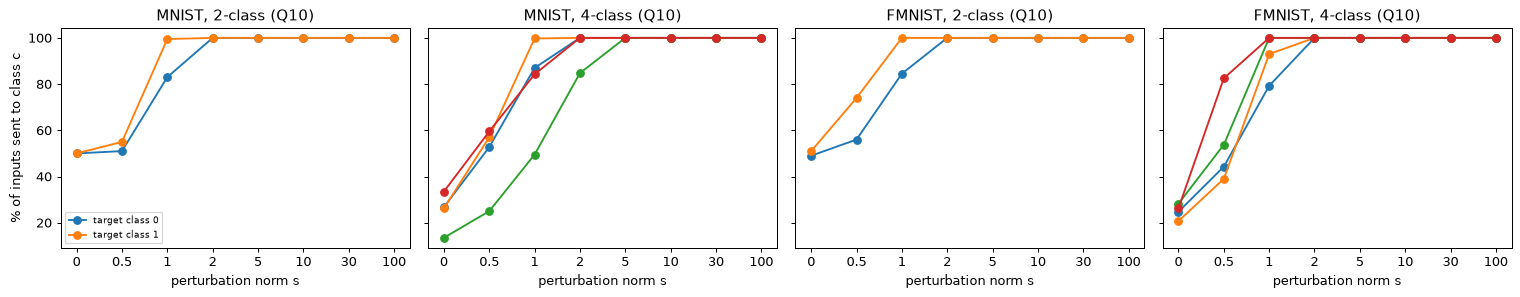

In [14]:
# ---- Theorem 1 (existence of additive UAPs): a large enough perturbation along a class-c sample sends ALL inputs to class c ---------------
# (pure amplitude-encoding statement: no pixel clipping here; the perturbation is added to the normalised amplitude vector and the sum is re-normalised)
SCALES = [0, 0.5, 1, 2, 5, 10, 30, 100]
rows = []
for (ds, k), M in MODELS.items():
    m = M["Q10"]; d, K = 2 ** D_IMG, 2 ** m["n_anc"]
    Xte_, yte_ = SETTINGS[(ds, k)]["te"]; Xtr_, ytr_ = SETTINGS[(ds, k)]["tr"]
    xa = amp_norm(torch.as_tensor(Xte_))
    with torch.no_grad():
        ptr = m["prob"](torch.as_tensor(Xtr_))
        for c in range(k):
            cand = np.where(ytr_ == c)[0]
            best = cand[int(ptr[cand, c].argmax())]               # most confidently correct training sample of class c
            phat = amp_norm(torch.as_tensor(Xtr_[best:best + 1]))
            for s in SCALES:
                pred = probs_from_wm(amp_norm(xa + s * phat), m["Wm"], d, K, k).argmax(1).numpy()
                rows.append(dict(ds=ds, k=k, target_class=c, scale=s, share_to_c=100.0 * float((pred == c).mean())))
TH = pd.DataFrame(rows)
tab = TH.groupby(["ds", "k", "scale"]).share_to_c.mean().unstack("scale")
print("Share (%) of ALL test inputs classified as the perturbation's class c after adding  s * (unit sample of class c)  and re-normalising;")
print("averaged over the target classes c; columns = perturbation norm s.  Theorem 1 predicts 100 % once s is large enough.")
display(tab.round(1))
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4), sharey=True)
for a, (ds, k) in zip(ax, MODELS):
    for c in range(k):
        t = TH[(TH.ds == ds) & (TH.k == k) & (TH.target_class == c)]
        a.plot(np.arange(len(SCALES)), t.share_to_c, marker="o", label=f"target class {c}")
    a.set_xticks(range(len(SCALES))); a.set_xticklabels(SCALES); a.set_xlabel("perturbation norm s"); a.set_title(f"{ds}, {k}-class (Q10)")
ax[0].set_ylabel("% of inputs sent to class c"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

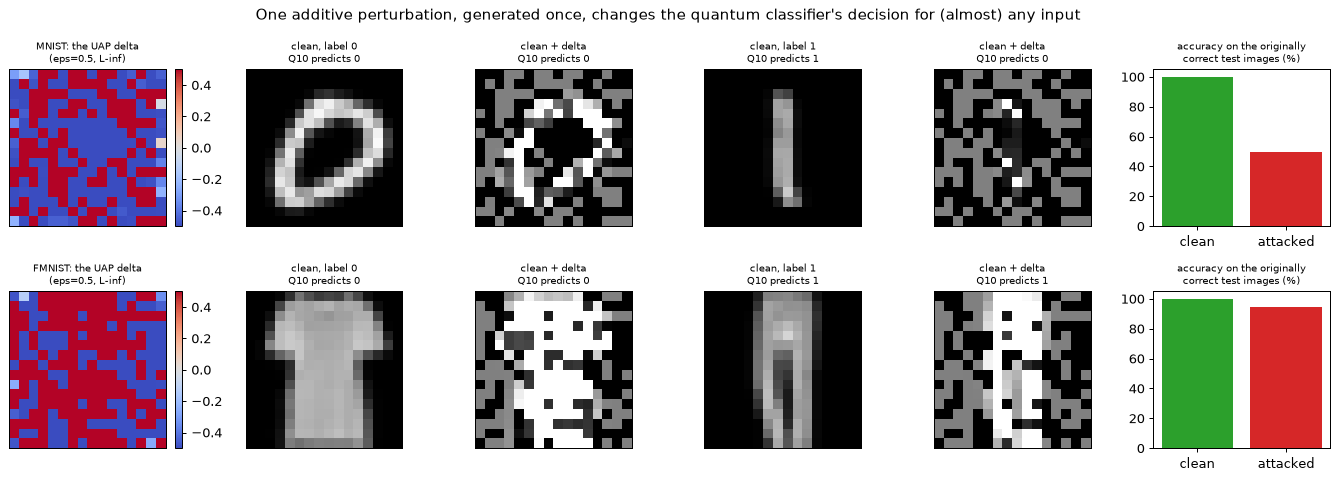

In [15]:
# ---- What do the universal perturbations look like? (Q10, MNIST and FMNIST, binary) ----------------------------------------------------------
fig, ax = plt.subplots(2, 6, figsize=(15, 5.4))
for r, ds in enumerate(["MNIST", "FMNIST"]):
    m = MODELS[(ds, 2)]["Q10"]; X, y = SETTINGS[(ds, 2)]["te"]
    eps = EPS_LIST[min(3, len(EPS_LIST) - 1)]
    delta = DELTAS[(ds, 2, "Q10", eps)]
    Xc, yc = clean_correct(m, X, y)
    Xa = apply_uap(Xc, delta)
    p0, p1 = predict_labels(m, Xc), predict_labels(m, Xa)
    im = ax[r, 0].imshow(delta.reshape(IMG, IMG), cmap="coolwarm", vmin=-eps, vmax=eps); ax[r, 0].set_title(f"{ds}: the UAP delta\n(eps={eps}, L-inf)", fontsize=8)
    plt.colorbar(im, ax=ax[r, 0], fraction=0.046)
    for j, cls in enumerate([0, 1]):
        i = np.where(yc == cls)[0][0]
        ax[r, 1 + 2 * j].imshow(Xc[i].reshape(IMG, IMG), cmap="gray", vmin=0, vmax=1); ax[r, 1 + 2 * j].set_title(f"clean, label {cls}\nQ10 predicts {p0[i]}", fontsize=8)
        ax[r, 2 + 2 * j].imshow(Xa[i].reshape(IMG, IMG), cmap="gray", vmin=0, vmax=1); ax[r, 2 + 2 * j].set_title(f"clean + delta\nQ10 predicts {p1[i]}", fontsize=8)
    ax[r, 5].bar(["clean", "attacked"], [100.0, 100 * float((p1 == yc).mean())], color=["tab:green", "tab:red"]); ax[r, 5].set_ylim(0, 105)
    ax[r, 5].set_title("accuracy on the originally\ncorrect test images (%)", fontsize=8)
    for a in ax[r, :5]: a.set_xticks([]); a.set_yticks([])
plt.suptitle("One additive perturbation, generated once, changes the quantum classifier's decision for (almost) any input"); plt.tight_layout(); plt.show()

## 5. QuGAP-U: unitary universal perturbations

**Quantum data.** The unitary attack acts on the quantum state directly, so it needs inputs that are states: the TIM ground states (4 qubits) and the 8 x 8 MNIST digits 0/1 amplitude-encoded on 6 qubits, each with one ancilla qubit and a depth-10 (and, in the full run, depth-20) classifier.

**Generator.** `quganp_u_classical` is the paper's classical simulation (a d x d matrix kept unitary by an SVD projection after each step); `quganp_u_pqc` replaces it by a PQC generator (layers of `Rot` and an `IsingZZ` ring) trained with Adam. Both minimise
`L_U = L_fool + alpha * L_fid` with `L_fid = (1 - F)^2`. Fidelity is the average of |<psi|U psi>|^2 over the attacked samples. A sweep of alpha produces a whole fidelity-misclassification trade-off curve.

**Baseline.** `qbim` is our re-implementation of qBIM: one layer of local rotations kept near the identity by a box constraint on the angles, found by the basic iterative method.

Hyper-parameters (alpha, qBIM budget) are chosen on the **validation** split only; the numbers reported are on the test split.

In [16]:
# ---- quantum-data tasks for the unitary attack: TIM phases (4 qubits) and 8 x 8 MNIST digits 0 vs 1 (6 qubits) ----------------------------------------
def unit_rows(X):
    X = np.asarray(X, dtype=np.float32).reshape(len(X), -1)
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)

pm = POOLS["MNIST"]
QDATA = {"TIM": dict(n_data=TIM_QUBITS, g_layers=G_LAYERS_TIM,
                     **{s: (unit_rows(TIM[s][0]), TIM[s][1]) for s in ["tr", "va", "te"]}),
         "MNIST8": dict(n_data=M8_QUBITS, g_layers=G_LAYERS_M8,
                        **{s: (unit_rows(pm[f"X8_{s}"][pm[f"y_{s}"] < 2]), pm[f"y_{s}"][pm[f"y_{s}"] < 2].astype(np.int64)) for s in ["tr", "va", "te"]})}

QCLF = {}      # (task, depth) -> trained classifier on quantum data
rows = []
for task, T in QDATA.items():
    n_data = T["n_data"]; d = 2 ** n_data
    for depth in QU_DEPTHS:
        W = train_q(T["tr"][0], T["tr"][1], n_data, 1, 2, depth, SEED)
        Wm = qmatrix(W, d, 2)
        acc = {s: float((probs_from_wm(torch.as_tensor(T[s][0]), Wm, d, 2, 2).argmax(1).numpy() == T[s][1]).mean()) for s in ["tr", "va", "te"]}
        QCLF[(task, depth)] = dict(W=W, Wm=Wm, acc=acc)
        rows.append(dict(task=task, classifier_depth=depth, qubits=f"{n_data} data + 1 ancilla", train_acc=acc["tr"], val_acc=acc["va"], test_acc=acc["te"]))
display(pd.DataFrame(rows).round(3))

,task,classifier_depth,qubits,train_acc,val_acc,test_acc
0,TIM,10,4 data + 1 ancilla,0.945,0.890,0.915
1,MNIST8,10,6 data + 1 ancilla,0.987,0.979,1.000


In [17]:
def to_c(psi):
    return torch.as_tensor(psi, dtype=torch.float32).to(CDT)

def fidelity(psi, phi):
    """F(|psi>, |phi>) = |<psi|phi>|^2 for a batch of states."""
    ov = (psi.conj() * phi).sum(1)
    return ov.real ** 2 + ov.imag ** 2

def u_loss(phi, psi, y, Wm, d, alpha):
    """L_U = L_fool + alpha * L_fid  with  L_fool = - CE  (untargeted)  and  L_fid = (1 - F)^2  (paper, Eq. for QuGAP-U)."""
    p = probs_from_wm(phi, Wm, d, 2, 2)
    l_fool = torch.log(p.gather(1, y[:, None]) + 1e-6).mean()
    F_ = fidelity(psi, phi)
    return l_fool + alpha * ((1 - F_) ** 2).mean(), F_

def correct_subset(X, y, Wm, d):
    ok = probs_from_wm(torch.as_tensor(X), Wm, d, 2, 2).argmax(1).numpy() == y
    return X[ok], y[ok]

def evaluate_unitary(apply_fn, task, depth):
    """Average fidelity and misclassification rate (share of correctly classified samples that are misclassified) on val and test."""
    T, C = QDATA[task], QCLF[(task, depth)]; d = 2 ** T["n_data"]
    out = {}
    with torch.no_grad():
        for s in ["va", "te"]:
            Xc, yc = correct_subset(*T[s], C["Wm"], d)
            psi = to_c(Xc); phi = apply_fn(psi)
            pred = probs_from_wm(phi, C["Wm"], d, 2, 2).argmax(1).numpy()
            out[f"fid_{s}"] = float(fidelity(psi, phi).mean()); out[f"mis_{s}"] = 100.0 * float((pred != yc).mean())
    return out

def quganp_u_classical(task, depth, alpha, seed=SEED, steps=U_STEPS_CLASSICAL, lr=U_LR_CLASSICAL):
    """Classical simulation of QuGAP-U: optimise a d x d matrix U_G, projected onto the unitary group after every Adam step (Kiani et al.)."""
    T, C = QDATA[task], QCLF[(task, depth)]; d = 2 ** T["n_data"]
    Xc, yc = correct_subset(*T["tr"], C["Wm"], d)
    psi, y = to_c(Xc), torch.as_tensor(yc)
    torch.manual_seed(seed)
    U = torch.eye(d, dtype=CDT).clone().requires_grad_(True)               # CHOICE: start at the identity (fidelity 1)
    opt = torch.optim.SGD([U], lr=lr, momentum=0.9)                          # CHOICE: plain gradient steps + projection (Kiani et al.); Adam would move every matrix entry by lr per step and cannot stay near the identity
    for _ in range(steps):
        loss, _ = u_loss(psi @ U.T, psi, y, C["Wm"], d, alpha)
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():                                               # project to the nearest unitary (polar decomposition)
            u_, _, vh = torch.linalg.svd(U); U.copy_(u_ @ vh)
    Uf = U.detach()
    return dict(U=Uf, **evaluate_unitary(lambda p_: p_ @ Uf.T, task, depth))

def quganp_u_pqc(task, depth, alpha, seed=SEED, steps=U_STEPS_PQC, lr=U_LR_PQC, g_layers=None):
    """QuGAP-U with a PQC generator (layers of Rot + IsingZZ ring on the data qubits), trained with Adam on L_fool + alpha * L_fid."""
    T, C = QDATA[task], QCLF[(task, depth)]; n = T["n_data"]; d = 2 ** n
    L = g_layers or T["g_layers"]
    Xc, yc = correct_subset(*T["tr"], C["Wm"], d)
    psi, y = to_c(Xc), torch.as_tensor(yc)
    gen = torch.Generator().manual_seed(seed)
    Wg = (0.01 * torch.randn(L, n, 4, generator=gen)).requires_grad_()      # CHOICE: tiny random angles (the generator starts near the identity)
    opt = torch.optim.Adam([Wg], lr=lr)
    for _ in range(steps):
        loss, _ = u_loss(gen_apply(psi, Wg), psi, y, C["Wm"], d, alpha)
        opt.zero_grad(); loss.backward(); opt.step()
    Wf = Wg.detach()
    with torch.no_grad():
        return dict(Wg=Wf, **evaluate_unitary(lambda p_: gen_apply(p_, Wf), task, depth))

def qbim(task, depth, budget, iters=20, seed=SEED):
    """qBIM-style baseline (Gong & Deng 2022, Lu et al. 2020): ONE layer of local single-qubit rotations kept near the identity
    (all angles in [-budget, budget]), found by a basic iterative method: signed-gradient ascent on the fooling loss, clipped to the box."""
    T, C = QDATA[task], QCLF[(task, depth)]; n = T["n_data"]; d = 2 ** n
    Xc, yc = correct_subset(*T["tr"], C["Wm"], d)
    psi, y = to_c(Xc), torch.as_tensor(yc)
    th = torch.zeros(1, n, 3, requires_grad=True)
    step = budget / 5
    for _ in range(iters):
        p = probs_from_wm(sel_apply(psi, th, entangle=False), C["Wm"], d, 2, 2)
        loss = torch.log(p.gather(1, y[:, None]) + 1e-6).mean()            # minimise -CE
        g, = torch.autograd.grad(loss, th)
        with torch.no_grad():
            th -= step * g.sign(); th.clamp_(-budget, budget)
    thf = th.detach()
    with torch.no_grad():
        return dict(theta=thf, **evaluate_unitary(lambda p_: sel_apply(p_, thf, entangle=False), task, depth))

In [18]:
t0 = time.time()
U_RES, U_KEEP = [], {}
for task in QDATA:
    for depth in QU_DEPTHS:
        # --- classical simulation of QuGAP-U (paper Fig. 4): only for the first (depth-10) classifier ---
        if depth == QU_DEPTHS[0]:
            for alpha in ALPHAS:
                r = quganp_u_classical(task, depth, alpha)
                U_KEEP[("classical", task, depth, alpha)] = r.pop("U")
                U_RES.append(dict(method="QuGAP-U classical simulation", task=task, clf_depth=depth, param=alpha, **r))
        # --- QuGAP-U with a PQC generator (paper Fig. 5 and Table 1) ---
        for alpha in ALPHAS:
            r = quganp_u_pqc(task, depth, alpha)
            U_KEEP[("pqc", task, depth, alpha)] = r.pop("Wg")
            U_RES.append(dict(method="QuGAP-U PQC generator", task=task, clf_depth=depth, param=alpha, **r))
            print(f"[{time.time() - t0:6.0f}s] {task} Q{depth} alpha={alpha:g}: val fidelity {r['fid_va']:.3f}, val misclassification {r['mis_va']:.1f} %")
        # --- qBIM baseline (one layer of local rotations near the identity) ---
        for b in QBIM_BUDGETS:
            r = qbim(task, depth, b)
            r.pop("theta")
            U_RES.append(dict(method="qBIM", task=task, clf_depth=depth, param=b, **r))
URES = pd.DataFrame(U_RES)
display(URES.round(3).head(12))
print(f"{len(URES)} unitary-attack runs in {time.time() - t0:.0f} s")

[    71s] TIM Q10 alpha=1: val fidelity 0.520, val misclassification 49.4 %


[    96s] TIM Q10 alpha=2: val fidelity 0.551, val misclassification 58.4 %


[   120s] TIM Q10 alpha=3: val fidelity 0.582, val misclassification 65.2 %


[   142s] TIM Q10 alpha=4: val fidelity 0.596, val misclassification 85.4 %


[   162s] TIM Q10 alpha=6: val fidelity 0.800, val misclassification 49.4 %


...

[   853s] MNIST8 Q10 alpha=16: val fidelity 0.961, val misclassification 1.1 %


[   914s] MNIST8 Q10 alpha=24: val fidelity 0.977, val misclassification 0.0 %


[   980s] MNIST8 Q10 alpha=32: val fidelity 0.969, val misclassification 0.0 %


,method,task,clf_depth,param,fid_va,mis_va,fid_te,mis_te
0,QuGAP-U classical simulation,TIM,10,1.0,0.505,49.438,0.460,58.470
1,QuGAP-U classical simulation,TIM,10,2.0,0.517,65.730,0.469,75.410
2,QuGAP-U classical simulation,TIM,10,3.0,0.609,61.798,0.615,55.738
3,QuGAP-U classical simulation,TIM,10,4.0,0.665,86.517,0.621,94.536
4,QuGAP-U classical simulation,TIM,10,6.0,0.558,58.427,0.506,67.760
5,QuGAP-U classical simulation,TIM,10,8.0,0.858,49.438,0.842,58.470
6,QuGAP-U classical simulation,TIM,10,12.0,0.942,7.865,0.938,10.383
7,QuGAP-U classical simulation,TIM,10,16.0,0.950,6.180,0.946,7.650
8,QuGAP-U classical simulation,TIM,10,24.0,0.958,3.933,0.956,4.372
9,QuGAP-U classical simulation,TIM,10,32.0,0.968,1.685,0.966,2.732


64 unitary-attack runs in 988 s


### Re-drawing Fig. 4 (classical simulation) and Fig. 5 (PQC generators)

Each point is one trained attack (one value of alpha, or one qBIM budget); the x-axis is the average fidelity of the attacked test states and the y-axis the misclassification rate. Fig. 4 of the paper
plots the classical simulation, Fig. 5 the PQC generator for classifiers of depth 10 and 20.

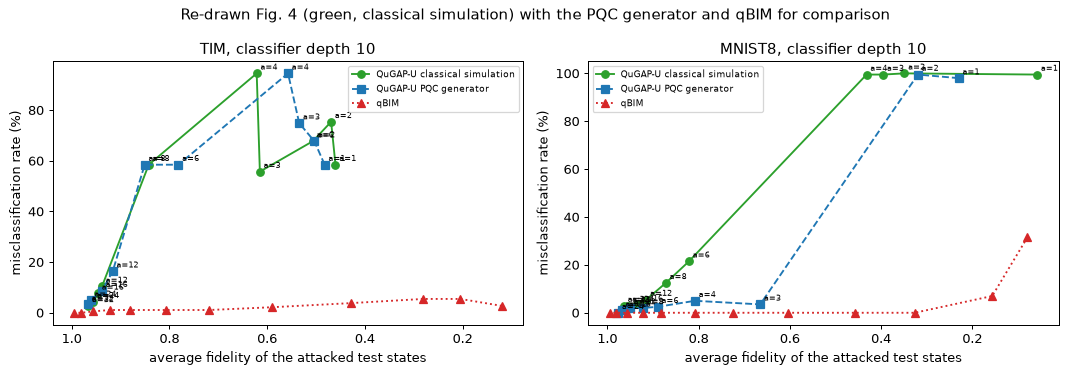

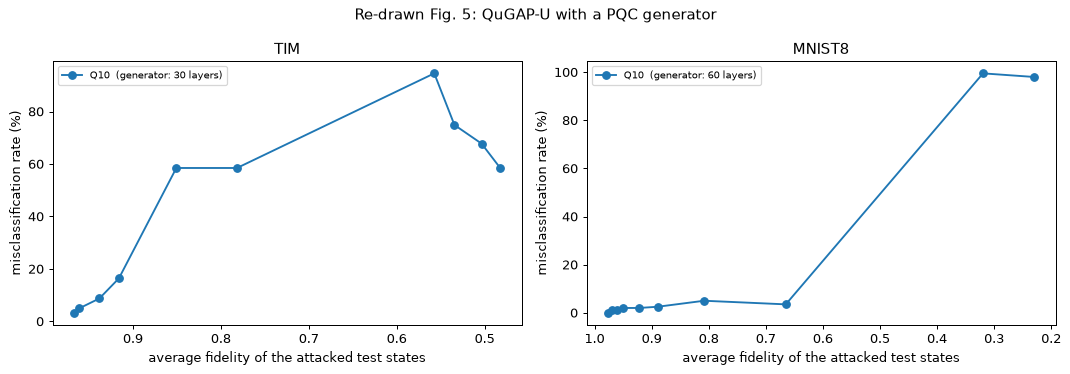

fid_te       mis_te       
                                          min   max    min    max
task   method                clf_depth                           
MNIST8 QuGAP-U PQC generator 10          0.23  0.98   0.00  99.50
       qBIM                  10          0.08  1.00   0.00  31.50
TIM    QuGAP-U PQC generator 10          0.48  0.97   3.28  94.54
       qBIM                  10          0.12  1.00   0.00   5.46

In [19]:
d0 = QU_DEPTHS[0]
# ---- Fig. 4: classical simulation (misclassification versus average fidelity, one point per alpha) -----------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, task in zip(ax, QDATA):
    for meth, mk, col in [("QuGAP-U classical simulation", "o-", "tab:green"), ("QuGAP-U PQC generator", "s--", "tab:blue"), ("qBIM", "^:", "tab:red")]:
        s = URES[(URES.method == meth) & (URES.task == task) & (URES.clf_depth == d0)].sort_values("fid_te")
        a.plot(s.fid_te, s.mis_te, mk, color=col, label=meth)
        if meth != "qBIM":
            for _, r in s.iterrows(): a.annotate(f"a={r.param:g}", (r.fid_te, r.mis_te), fontsize=6, xytext=(3, 3), textcoords="offset points")
    a.set_xlabel("average fidelity of the attacked test states"); a.set_ylabel("misclassification rate (%)"); a.set_title(f"{task}, classifier depth {d0}")
    a.invert_xaxis(); a.legend(fontsize=7)
plt.suptitle("Re-drawn Fig. 4 (green, classical simulation) with the PQC generator and qBIM for comparison"); plt.tight_layout(); plt.show()

# ---- Fig. 5: PQC generator against classifiers of depth 10 and 20 ------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, task in zip(ax, QDATA):
    for dep in QU_DEPTHS:
        s = URES[(URES.method == "QuGAP-U PQC generator") & (URES.task == task) & (URES.clf_depth == dep)].sort_values("fid_te")
        a.plot(s.fid_te, s.mis_te, "o-", label=f"Q{dep}  (generator: {QDATA[task]['g_layers']} layers)")
    a.set_xlabel("average fidelity of the attacked test states"); a.set_ylabel("misclassification rate (%)"); a.set_title(task)
    a.invert_xaxis(); a.legend(fontsize=8)
plt.suptitle("Re-drawn Fig. 5: QuGAP-U with a PQC generator"); plt.tight_layout(); plt.show()
display(URES[URES.method != "QuGAP-U classical simulation"].groupby(["task", "method", "clf_depth"])[["fid_te", "mis_te"]].agg(["min", "max"]).round(2))

### Table 1 recomputed

For every fidelity constraint the notebook takes, among all attacks of a method, those whose validation average fidelity is at least the constraint, picks the one with the largest validation misclassification rate and
reports its **test** misclassification rate (0.00 if no attack satisfies the constraint). The paper's numbers are shown beside it; "within" means within 5 percentage points.

In [20]:
PAPER_T1 = {   # paper, Table 1 (classifier depth 10): misclassification rate (%) for fidelity constraints 0.95 ... 0.70
    ("TIM", "qBIM"):    [3.18, 6.37, 9.44, 13.39, 16.68, 23.27],
    ("TIM", "QuGAP-U"): [10.54, 54.88, 54.88, 54.88, 54.88, 54.88],
    ("MNIST8", "qBIM"):    [0.00, 0.00, 0.00, 0.00, 0.05, 0.15],
    ("MNIST8", "QuGAP-U"): [0.00, 0.00, 12.56, 36.65, 50.78, 54.97],
}
METH = {"qBIM": "qBIM", "QuGAP-U": "QuGAP-U PQC generator"}

def table1_value(method, task, fmin, depth=QU_DEPTHS[0]):
    """Largest validation misclassification among runs whose validation average fidelity >= fmin; returns the test numbers of that run."""
    s = URES[(URES.method == METH[method]) & (URES.task == task) & (URES.clf_depth == depth) & (URES.fid_va >= fmin)]
    if len(s) == 0:
        return 0.0, float("nan")
    r = s.loc[s.mis_va.idxmax()]
    return float(r.mis_te), float(r.fid_te)

rows, T1_CMP = [], []
for i, fc in enumerate(FID_CONSTRAINTS):
    row = {"fidelity constraint": fc}
    for task in QDATA:
        for method in ["qBIM", "QuGAP-U"]:
            mis, fid = table1_value(method, task, fc)
            pap = PAPER_T1[(task, method)][i]
            row[f"{task} {method} paper"] = pap; row[f"{task} {method} here"] = round(mis, 2)
            T1_CMP.append(dict(task=task, method=method, constraint=fc, paper=pap, here=mis, test_fidelity=fid))
    rows.append(row)
display(pd.DataFrame(rows))
T1 = pd.DataFrame(T1_CMP)
T1["within_tol"] = (T1.paper - T1.here).abs() <= TOL_RATE
print(f"{int(T1.within_tol.sum())} of {len(T1)} Table-1 entries are within {TOL_RATE:g} percentage points of the paper.")
print(T1.groupby(["task", "method"]).within_tol.sum().rename("entries within tolerance (of 6)").to_string())

,fidelity constraint,TIM qBIM paper,TIM qBIM here,TIM QuGAP-U paper,TIM QuGAP-U here,MNIST8 qBIM paper,MNIST8 qBIM here,MNIST8 QuGAP-U paper,MNIST8 QuGAP-U here
0,0.95,3.18,0.00,10.54,4.92,0.00,0.0,0.00,2.0
1,0.90,6.37,0.00,54.88,16.39,0.00,0.0,0.00,2.0
2,0.85,9.44,0.00,54.88,58.47,0.00,0.0,12.56,2.5
3,0.80,13.39,1.09,54.88,58.47,0.00,0.0,36.65,5.0
4,0.75,16.68,1.09,54.88,58.47,0.05,0.0,50.78,5.0
5,0.70,23.27,1.09,54.88,58.47,0.15,0.0,54.97,5.0


13 of 24 Table-1 entries are within 5 percentage points of the paper.
task    method 
MNIST8  QuGAP-U    2
        qBIM       6
TIM     QuGAP-U    4
        qBIM       1


## Quantum Circuit Architecture

Every circuit below is built by the same functions that produced (or evaluated) the results: the amplitude-encoded classifier (`make_clf_qnode`) and the QuGAP-U pipeline generator + classifier (`make_attack_qnode`).

* The **first drawing of each pair** is the real PennyLane QNode with its trained weights, template-level (`AmplitudeEmbedding` / `StatePrep` box, `StronglyEntanglingLayers` box, probability read-out of the ancillas).
* The **second drawing** is the same circuit at gate level (`Rot` = one general rotation per qubit, then a ring of CNOTs per layer) for a two-layer prefix, because a 60-layer circuit would be several metres wide.
  A cell asserts that the gate list of the full circuit starts with exactly this prefix.
* The table prints, for each distinct architecture, the number of qubits, the circuit depth (from `qml.specs`) and the number of trainable angles.

Assumptions where the paper is silent: the ansatz is `StronglyEntanglingLayers` (3 angles per qubit and layer, CNOT ring with PennyLane's default ranges), the class is the bit string of the ancilla qubits (placed after the data qubits),
the generator (our own `RotZZLayers` operation: `Rot` on every qubit, then `IsingZZ` on the qubit ring, per layer) acts on the data qubits only and the ancilla is untouched until the classifier.

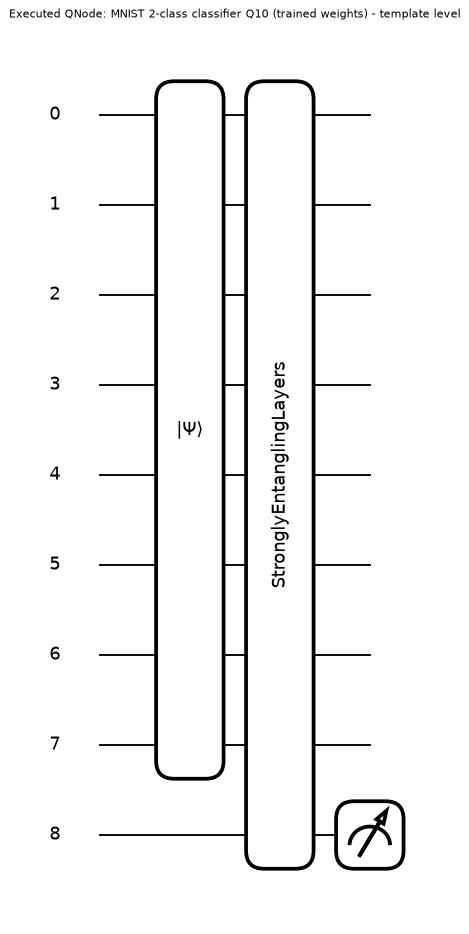

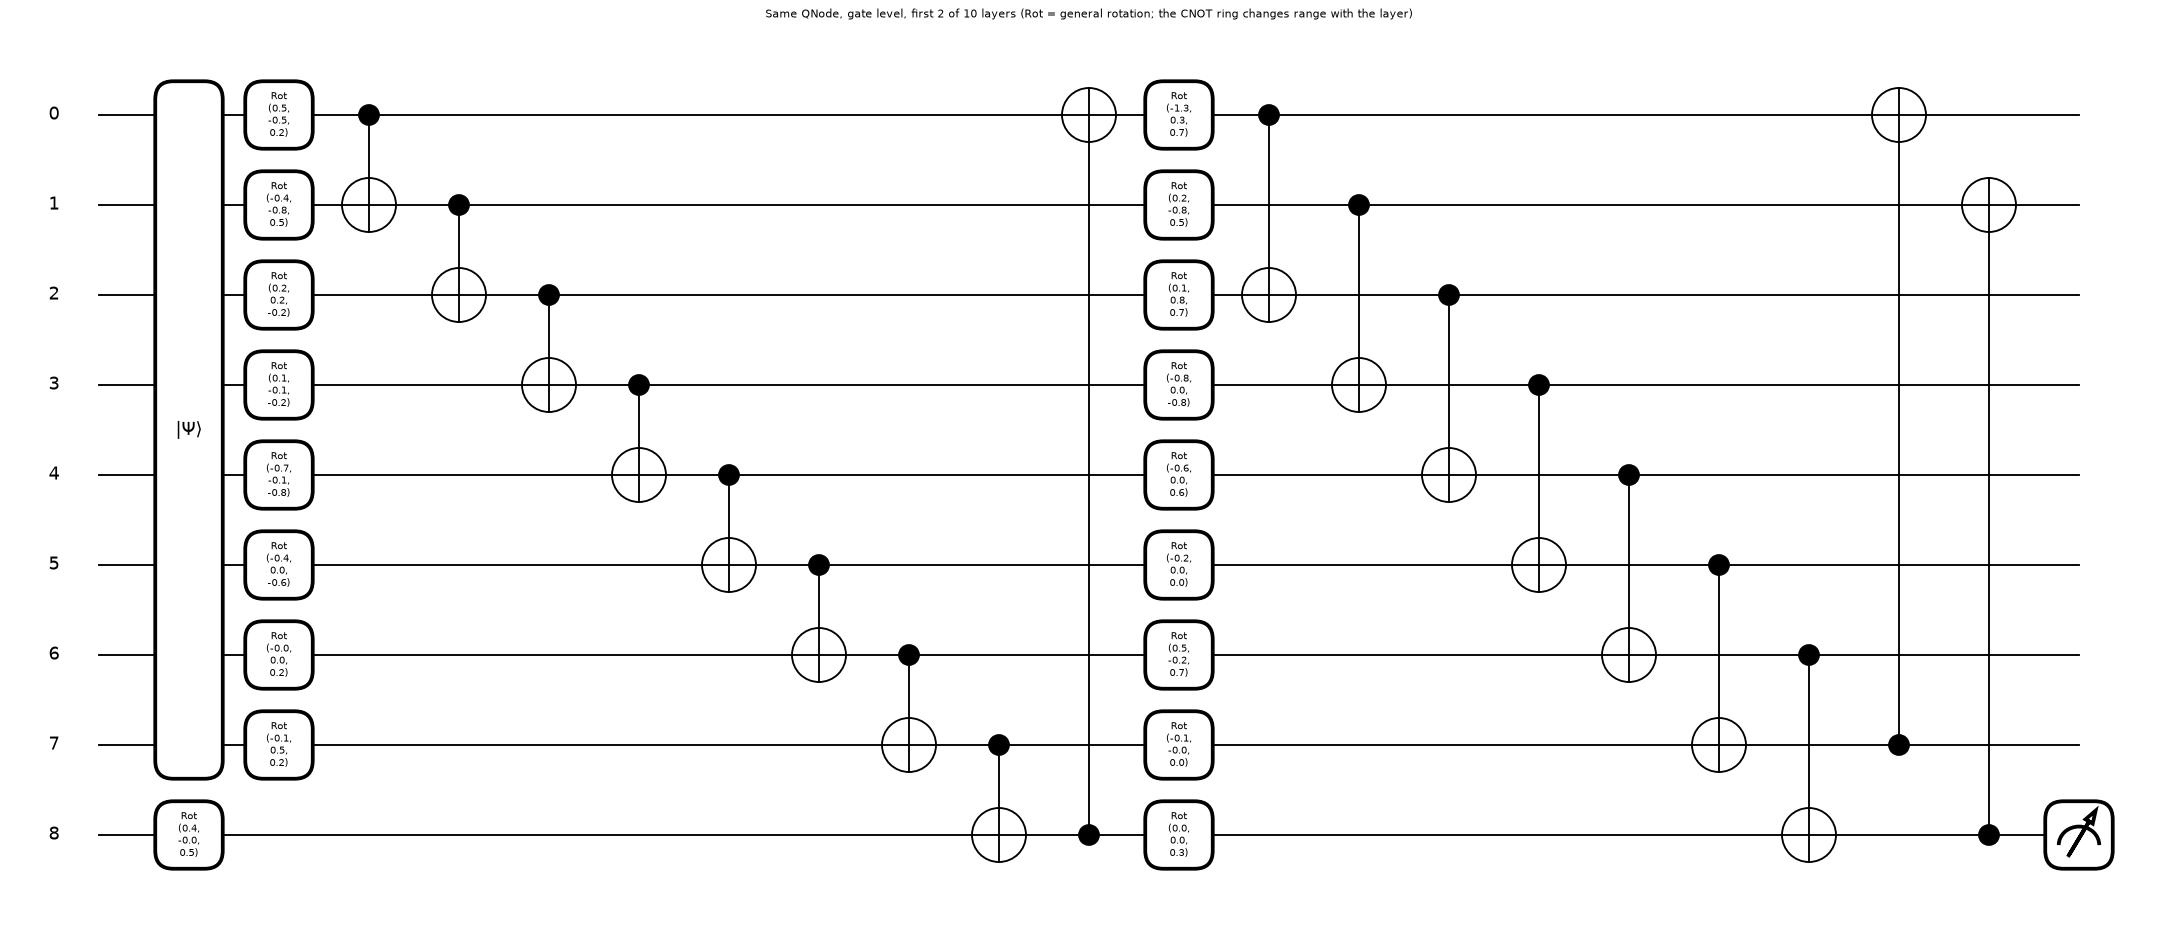

assertion passed: the first 37 gates of the depth-10 2-class QNode equal the gates drawn above



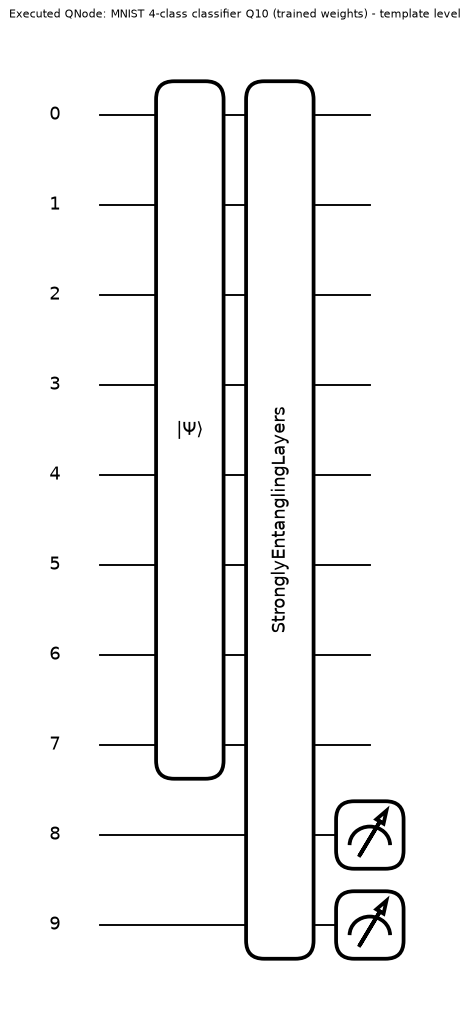

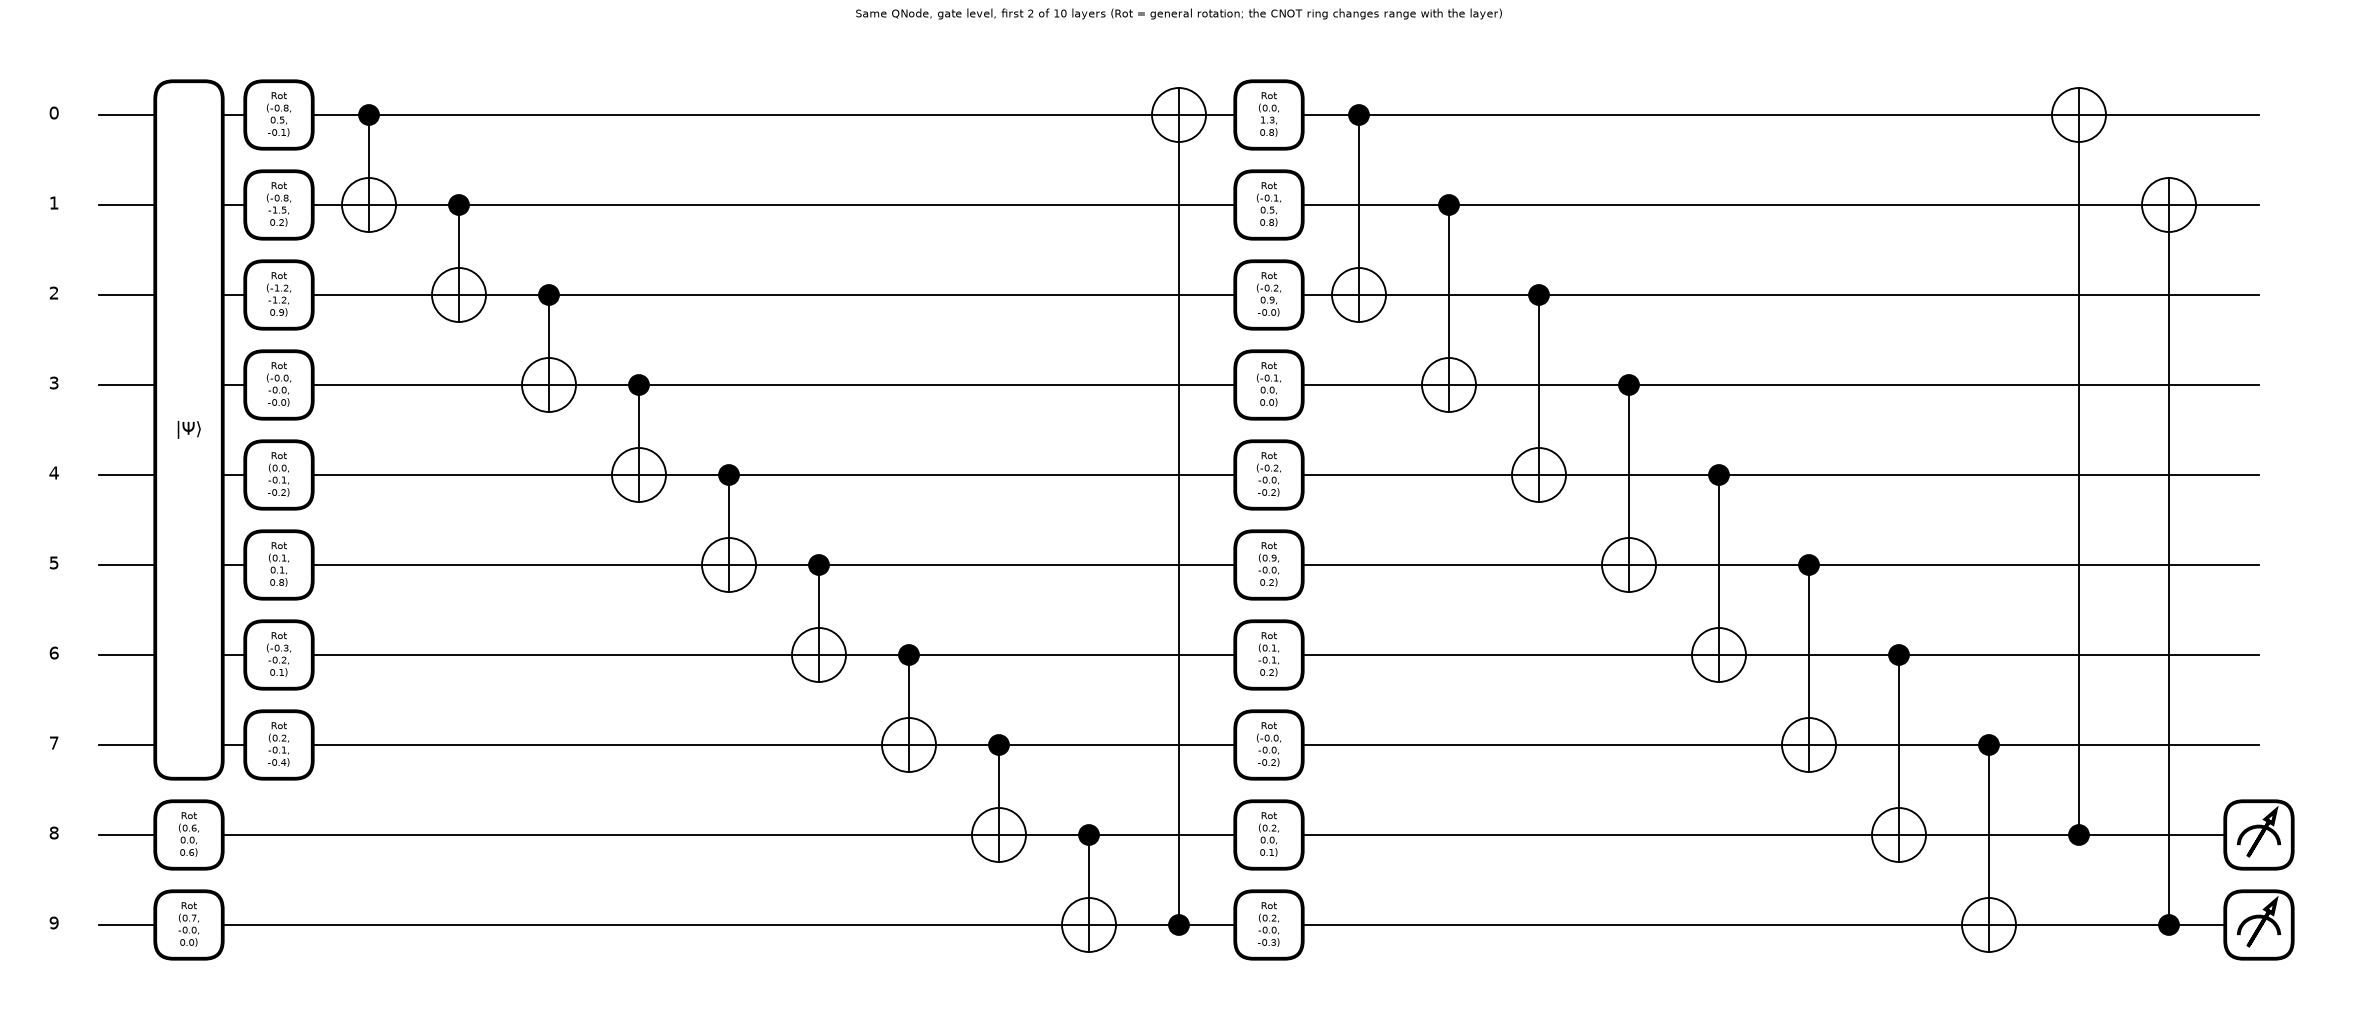

assertion passed: the first 41 gates of the depth-10 4-class QNode equal the gates drawn above



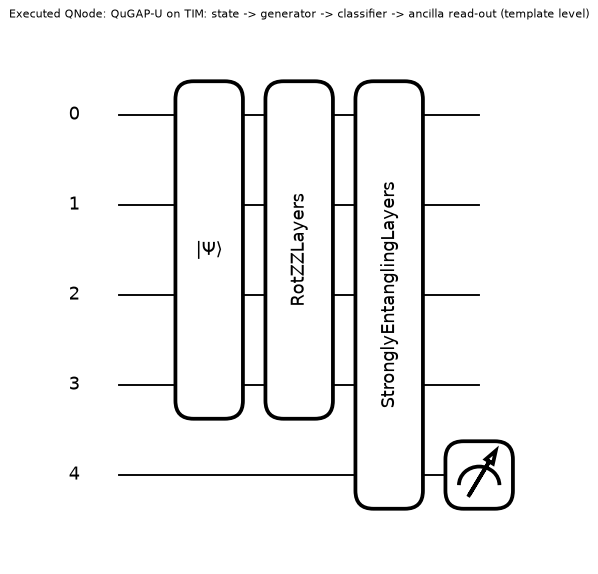

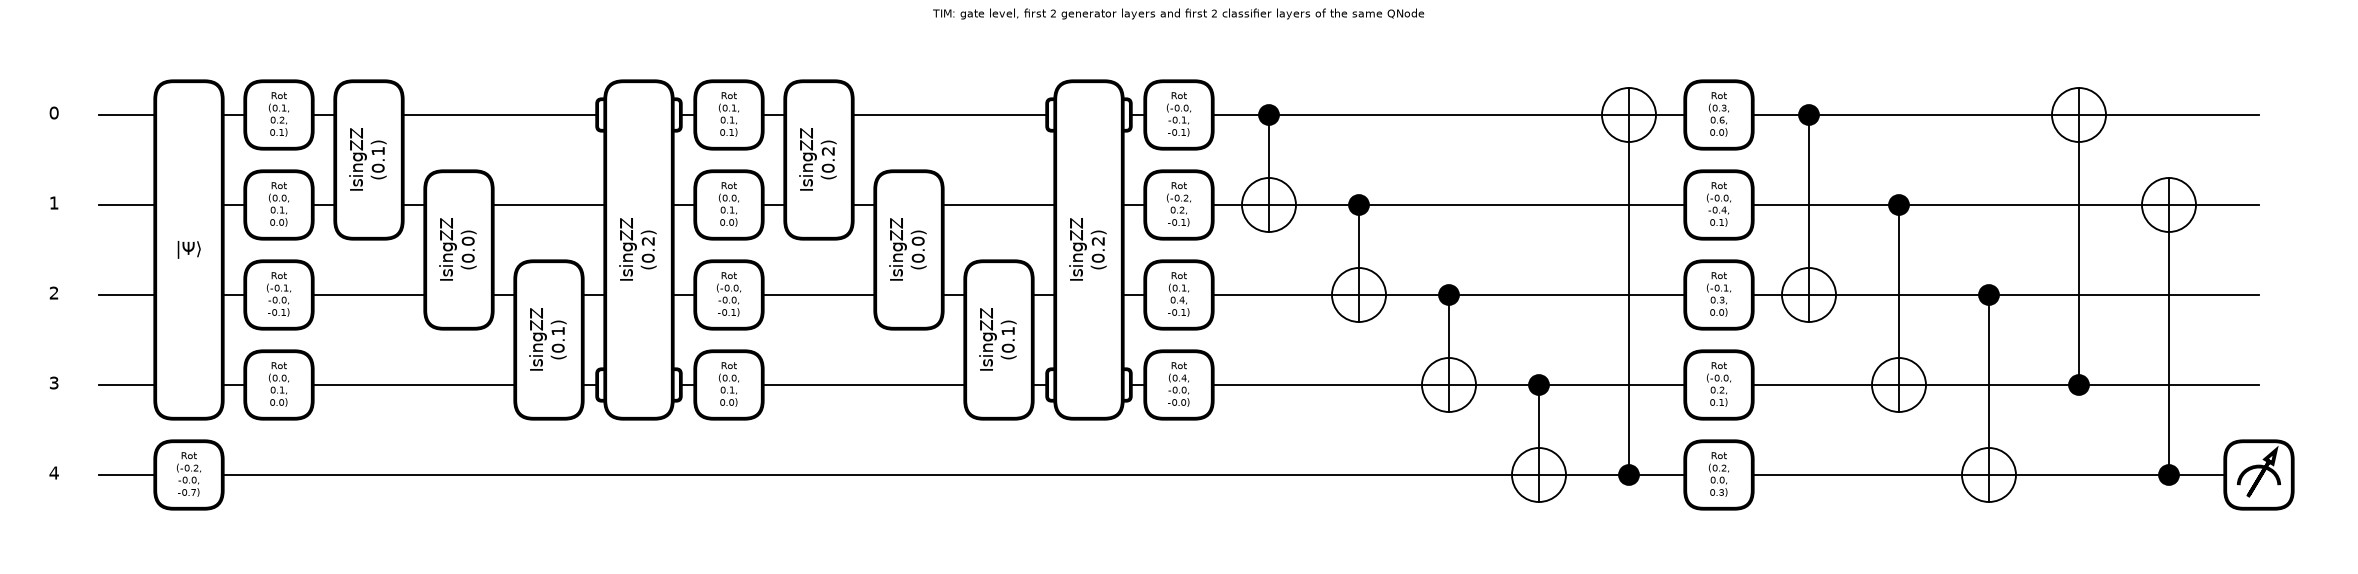

assertion passed: first generator layers and first classifier layers of the full TIM pipeline equal the gates drawn above



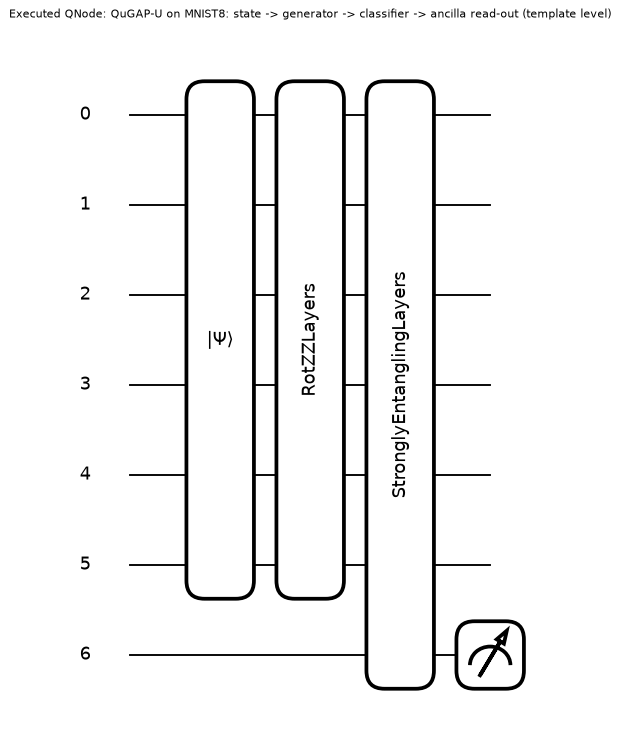

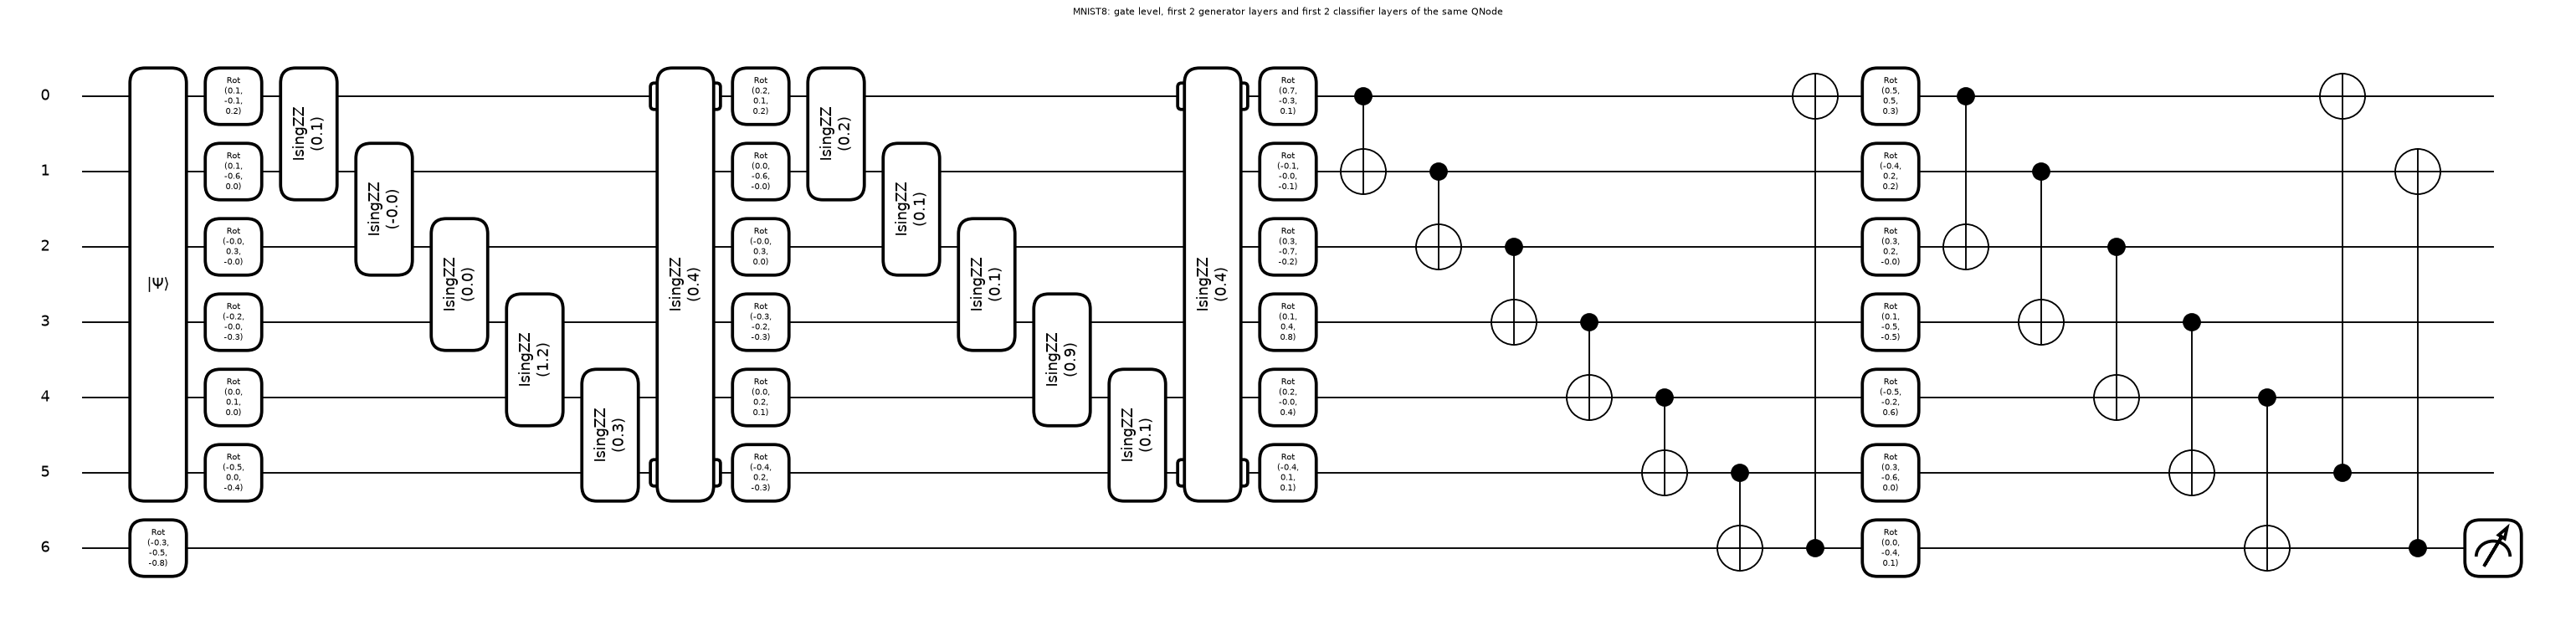

assertion passed: first generator layers and first classifier layers of the full MNIST8 pipeline equal the gates drawn above



,architecture,qubits,depth,gates,trainable_angles
0,"image classifier, 2 classes, depth 10",9,57,181,270
1,"image classifier, 2 classes, depth 20",9,104,361,540
2,"image classifier, 4 classes, depth 10",10,58,201,300
3,"image classifier, 4 classes, depth 20",10,110,401,600
4,QuGAP-U pipeline TIM: generator 30 layers + cl...,5,195,341,630
5,of which the trainable generator alone (TIM),4,-,-,480
6,QuGAP-U pipeline MNIST8: generator 60 layers +...,7,469,861,1650
7,of which the trainable generator alone (MNI...,6,-,-,1440


In [21]:
def device_ops(qnode, *args):
    """Operations of the circuit as the device executes it (templates decomposed into Rot and CNOT)."""
    batch, _ = qml.workflow.construct_batch(qnode, level="device")(*args)
    return batch[0].operations

def same_ops(a, b):
    return len(a) == len(b) and all(x.name == y.name and x.wires == y.wires and
                                    np.allclose([float(np.asarray(p).ravel()[0]) for p in x.data] if x.data and x.name != "StatePrep" else 0,
                                                [float(np.asarray(p).ravel()[0]) for p in y.data] if y.data and y.name != "StatePrep" else 0, atol=1e-6)
                                    for x, y in zip(a, b))

def arch_row(name, qnode, args, n_params):
    sp = qml.specs(qnode, level="device")(*args).resources
    return dict(architecture=name, qubits=sp.num_allocs, depth=sp.depth, gates=sp.num_gates, trainable_angles=n_params)

arch_rows, d = [], 2 ** D_IMG
# --- (1) amplitude-encoded classifiers on images (binary: 8+1 qubits, 4-class: 8+2 qubits), one per depth ---
for k in [2, 4]:
    n_anc = 1 if k == 2 else 2
    clf = make_clf_qnode(D_IMG, n_anc)
    x_ex = torch.as_tensor(SETTINGS[("MNIST", k)]["te"][0][0]).double()
    for depth in Q_DEPTHS:
        W = MODELS[("MNIST", k)][f"Q{depth}"]["W"].double()
        arch_rows.append(arch_row(f"image classifier, {k} classes, depth {depth}", clf, (x_ex, W), W.numel()))
    W10 = MODELS[("MNIST", k)]["Q10"]["W"].double()
    fig, ax = qml.draw_mpl(clf, level="top", decimals=2)(x_ex, W10)
    ax.set_title(f"Executed QNode: MNIST {k}-class classifier Q10 (trained weights) - template level", fontsize=9); plt.show()
    # gate-level drawing of a two-layer prefix + assertion that the depth-10 circuit starts with exactly these gates
    W2 = W10[:2]
    fig, ax = qml.draw_mpl(clf, level="device", decimals=1)(x_ex, W2)
    ax.set_title(f"Same QNode, gate level, first 2 of 10 layers (Rot = general rotation; the CNOT ring changes range with the layer)", fontsize=9); plt.show()
    full_ops, small_ops = device_ops(clf, x_ex, W10), device_ops(clf, x_ex, W2)
    n_pref = 1 + 2 * (D_IMG + n_anc) * 2
    assert same_ops(full_ops[:n_pref], small_ops), "gate-level drawing is not a prefix of the executed circuit"
    print(f"assertion passed: the first {n_pref} gates of the depth-10 {k}-class QNode equal the gates drawn above\n")

# --- (2) QuGAP-U pipelines: PQC generator on the data qubits followed by the classifier ---
for task, T in QDATA.items():
    n_data = T["n_data"]; d_t = 2 ** n_data
    att = make_attack_qnode(n_data, 1)
    psi_ex = torch.as_tensor(T["te"][0][0]).double()
    Wc = QCLF[(task, QU_DEPTHS[0])]["W"].double()
    Wg = U_KEEP[("pqc", task, QU_DEPTHS[0], ALPHAS[len(ALPHAS) // 2])].double()   # (L, n, 4)
    arch_rows.append(arch_row(f"QuGAP-U pipeline {task}: generator {Wg.shape[0]} layers + classifier {Wc.shape[0]} layers", att, (psi_ex, Wg, Wc), Wg.numel() + Wc.numel()))
    arch_rows.append(dict(architecture=f"   of which the trainable generator alone ({task})", qubits=n_data, depth="-", gates="-", trainable_angles=Wg.numel()))
    fig, ax = qml.draw_mpl(att, level="top", decimals=2)(psi_ex, Wg, Wc)
    ax.set_title(f"Executed QNode: QuGAP-U on {task}: state -> generator -> classifier -> ancilla read-out (template level)", fontsize=9); plt.show()
    fig, ax = qml.draw_mpl(att, level="device", decimals=1)(psi_ex, Wg[:2], Wc[:2])
    ax.set_title(f"{task}: gate level, first 2 generator layers and first 2 classifier layers of the same QNode", fontsize=9); plt.show()
    full_ops, small_ops = device_ops(att, psi_ex, Wg, Wc), device_ops(att, psi_ex, Wg[:2], Wc[:2])
    ng, nc = 2 * n_data * 2, 2 * (n_data + 1) * 2
    assert same_ops(full_ops[:1 + ng], small_ops[:1 + ng]), "generator prefix differs"
    off = 1 + 2 * n_data * Wg.shape[0]
    assert same_ops(full_ops[off:off + nc], small_ops[1 + ng:1 + ng + nc]), "classifier prefix differs"
    print(f"assertion passed: first generator layers and first classifier layers of the full {task} pipeline equal the gates drawn above\n")
ARCH = pd.DataFrame(arch_rows)
display(ARCH)

### Final confirmation with the real QNodes

The reported misclassification rates come from the exact simulator. Here the attacked inputs are pushed through the **real PennyLane QNodes** (the classifier QNode for a QuGAP-A perturbation, the generator + classifier
QNode for a QuGAP-U attack) and the predicted labels are compared with the simulator's: they must be identical.

In [22]:
N_CHECK = 60
rows = []
# (1) QuGAP-A: a frozen additive UAP, evaluated through the REAL classifier QNode
for (ds, k), M in MODELS.items():
    m = M["Q10"]
    X, y = SETTINGS[(ds, k)]["te"]
    Xc, yc = clean_correct(m, X, y); Xc, yc = Xc[:N_CHECK], yc[:N_CHECK]
    Xa = apply_uap(Xc, DELTAS[(ds, k, "Q10", EPS_T)])
    clf = make_clf_qnode(D_IMG, m["n_anc"])
    with torch.no_grad():
        pr = clf(torch.as_tensor(Xa).double(), m["W"].double())[:, :k]
    pred_qnode, pred_sim = pr.argmax(1).numpy(), predict_labels(m, Xa)
    assert (pred_qnode == pred_sim).all(), "QNode and simulator disagree"
    rows.append(dict(attack="QuGAP-A", setting=f"{ds} {k}-class, Q10, eps={EPS_T}", attacked_inputs=len(yc), qnode_misclassified=int((pred_qnode != yc).sum()),
                     simulator_misclassified=int((pred_sim != yc).sum()), predictions_identical=True))
# (2) QuGAP-U with a PQC generator, evaluated through the REAL generator + classifier QNode
for task, T in QDATA.items():
    n_data = T["n_data"]; d_t = 2 ** n_data; alpha = ALPHAS[len(ALPHAS) // 2]
    C = QCLF[(task, QU_DEPTHS[0])]; Wg = U_KEEP[("pqc", task, QU_DEPTHS[0], alpha)]
    Xc, yc = correct_subset(*T["te"], C["Wm"], d_t); Xc, yc = Xc[:N_CHECK], yc[:N_CHECK]
    att = make_attack_qnode(n_data, 1)
    with torch.no_grad():
        pr = att(torch.as_tensor(Xc).double(), Wg.double(), C["W"].double())
        pred_sim = probs_from_wm(gen_apply(to_c(Xc), Wg), C["Wm"], d_t, 2, 2).argmax(1).numpy()
    pred_qnode = pr.argmax(1).numpy()
    assert (pred_qnode == pred_sim).all(), "QNode and simulator disagree"
    rows.append(dict(attack="QuGAP-U (PQC)", setting=f"{task}, generator {Wg.shape[0]} layers, alpha={alpha:g}", attacked_inputs=len(yc), qnode_misclassified=int((pred_qnode != yc).sum()),
                     simulator_misclassified=int((pred_sim != yc).sum()), predictions_identical=True))
display(pd.DataFrame(rows))
print("All predictions of the real PennyLane QNodes equal those of the exact simulator.")

,attack,setting,attacked_inputs,qnode_misclassified,simulator_misclassified,predictions_identical
0,QuGAP-A,"MNIST 2-class, Q10, eps=0.5",60,30,30,True
1,QuGAP-A,"MNIST 4-class, Q10, eps=0.5",60,33,33,True
2,QuGAP-A,"FMNIST 2-class, Q10, eps=0.5",60,3,3,True
3,QuGAP-A,"FMNIST 4-class, Q10, eps=0.5",60,30,30,True
4,QuGAP-U (PQC),"TIM, generator 30 layers, alpha=8",60,30,30,True
5,QuGAP-U (PQC),"MNIST8, generator 60 layers, alpha=8",60,1,1,True


All predictions of the real PennyLane QNodes equal those of the exact simulator.


## 6. The paper's claims next to this notebook's numbers

Each claim gets one verdict: **reproduced** (within the stated tolerance or the stated qualitative behaviour is observed), **not reached here** / **exceeded here** (with the gap), or **cannot be checked** (no number in the text; the paper's figures are plots only).
Differences in the absolute misclassification rates are expected: the classifier training recipe, the generator network, the epsilon grid and the data subsets are choices of this notebook.

In [23]:
def verdict_rate(paper, here, tol=TOL_RATE):
    if abs(paper - here) <= tol: return "reproduced"
    return "exceeded here" if here > paper else "not reached here"

claims = []
def add(n, claim, paper, here, verdict):
    claims.append({"#": n, "claim": claim, "paper": paper, "this notebook": here, "verdict": verdict})

qnames = [f"Q{d}" for d in Q_DEPTHS]
emax = max(EPS_LIST)
curve = agg[agg.target.isin(qnames)]

# 1. monotone rise
ok, tot, worst = 0, 0, 0.0
for (ds, k, tg), s in curve.groupby(["ds", "k", "target"]):
    v = s.sort_values("eps")["mean"].values
    drop = float(np.max(np.maximum(0, v[:-1] - v[1:]))); worst = max(worst, drop)
    tot += 1; ok += int(v[-1] > v[0] and drop <= TOL_RATE)
add(1, "misclassification rises with epsilon (PQCs, both datasets)", "rising curves (Fig. 2)", f"{ok} of {tot} curves rise with no drop above {TOL_RATE:g} points (largest drop {worst:.1f})",
    "reproduced" if ok == tot else "not reached here")

# 2. plateau (k-1)/k per setting (mean over the quantum depths at the largest epsilon)
for (ds, k) in MODELS:
    here = float(curve[(curve.ds == ds) & (curve.k == k) & (curve.eps == emax)]["mean"].mean()); pap = 100 * (k - 1) / k
    add("2", f"plateau near (k-1)/k, {ds} {k}-class (mean over depths at eps = {emax})", f"about {pap:.0f} %", f"{here:.1f} %", verdict_rate(pap, here))

# 3. every depth vulnerable
last = curve[curve.eps == emax].copy(); last["plateau"] = 100.0 * (last.k - 1) / last.k
worst_m = float((last["mean"] / last["plateau"]).min())
add(3, "PQCs of every depth are vulnerable", "all depths reach the plateau", f"weakest model reaches {100 * worst_m:.0f} % of its plateau at eps = {emax}", "reproduced" if worst_m >= 0.8 else "not reached here")

# 4. Theorem 1
sh = TH[TH.scale == max(SCALES)].groupby(["ds", "k"]).share_to_c.mean()
add(4, "a large additive perturbation sends every input to one class (Theorem 1)", "100 % for a large enough norm", f"{sh.min():.1f} % (worst setting) at s = {max(SCALES)}", "reproduced" if sh.min() >= 95 else "not reached here")

# 5. transfer
wb, tr = TRANSFER["white_box_quantum"], TRANSFER["cnn_to_quantum"]
add(5, "UAPs of a classical CNN do not transfer well to the quantum classifier", "'do not transfer well' (numbers in the supplement)",
    f"CNN->quantum {tr:.1f} % vs white-box quantum {wb:.1f} %; quantum->CNN {TRANSFER['quantum_to_cnn']:.1f} % (CNN white-box {TRANSFER['cnn_white_box']:.1f} %)",
    "reproduced" if tr <= 0.5 * wb else "not reached here")

# 6. classical simulation: fidelity control and saturation values
cl = URES[URES.method == "QuGAP-U classical simulation"]
for task, pap_max, txt in [("MNIST8", 100.0, "approaches 100 % as alpha decreases"), ("TIM", 54.0, "stays at about 54 %")]:
    s = cl[cl.task == task]
    rho = float(s[["param", "fid_te"]].corr(method="spearman").iloc[0, 1])
    add("6a", f"classical simulation, {task}: alpha controls the fidelity monotonically", "fine-grained control (Fig. 4)", f"Spearman(alpha, fidelity) = {rho:.2f}", "reproduced" if rho >= 0.9 else "not reached here")
    add("6b", f"classical simulation, {task}: maximum misclassification", f"{txt}", f"{s.mis_te.max():.1f} % (at fidelity {s.loc[s.mis_te.idxmax(), 'fid_te']:.2f})", verdict_rate(pap_max, float(s.mis_te.max())))

# 7. Table 1, entry by entry summary
for (task, method), s in T1.groupby(["task", "method"]):
    n_ok = int(s.within_tol.sum())
    add(7, f"Table 1, {task}, {method} ({len(s)} fidelity constraints)", " / ".join(f"{v:g}" for v in s.paper), " / ".join(f"{v:.2f}".rstrip("0").rstrip(".") for v in s.here),
        "reproduced" if n_ok == len(s) else f"mixed: {n_ok} of {len(s)} within {TOL_RATE:g} points")

# 8. QuGAP-U vs qBIM
for task in QDATA:
    a = T1[(T1.task == task) & (T1.method == "QuGAP-U")].here.values; b = T1[(T1.task == task) & (T1.method == "qBIM")].here.values
    wins = int((a >= b).sum()); strict = int((a > b + 1e-9).sum())
    add(8, f"QuGAP-U is at least as strong as qBIM at every fidelity constraint ({task})", "QuGAP-U > qBIM at all constraints",
        f"QuGAP-U >= qBIM at {wins} of {len(a)} constraints (strictly better at {strict})", "reproduced" if wins == len(a) else "not reached here")

# 9. TIM saturation between 0.90 and 0.70
a = T1[(T1.task == "TIM") & (T1.method == "QuGAP-U")].set_index("constraint").here
plateau_vals = a.loc[[c for c in FID_CONSTRAINTS if c <= 0.90]]
add(9, "TIM: misclassification saturates from fidelity 0.90 downwards, with a steep rise between 0.95 and 0.90", "10.5 -> 54.9 -> 54.9 ... 54.9",
    f"{a.loc[0.95]:.1f} -> " + " -> ".join(f"{v:.1f}" for v in plateau_vals),
    "reproduced" if (plateau_vals.max() - plateau_vals.min() <= 3 and plateau_vals.iloc[0] - a.loc[0.95] >= 10) else "not reached here")

# 10. MNIST: PQC generator weaker than the classical simulation
def classical_at(task, fmin):
    s = cl[(cl.task == task) & (cl.fid_va >= fmin)]
    return float(s.loc[s.mis_va.idxmax()].mis_te) if len(s) else 0.0
diffs = [classical_at("MNIST8", fc) - table1_value("QuGAP-U", "MNIST8", fc)[0] for fc in FID_CONSTRAINTS]
add(10, "MNIST 8 x 8: the PQC generator is weaker than the classical simulation at the same fidelity", "weaker (compare Fig. 4b with Fig. 5b)",
    f"classical minus PQC, mean over the constraints: {np.mean(diffs):+.1f} points", "reproduced" if np.mean(diffs) > 0 else "not reached here")

# 11. numbers only given in plots
add(11, "exact curves of Fig. 2 / 4 / 5 for each depth and dataset", "plots without printed values", "re-drawn above", "cannot be checked")

VERD = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 140)
print(VERD.to_string(index=False))
print(VERD.verdict.str.split(":").str[0].value_counts().to_string())
print(f"\nTotal notebook time: {(time.time() - T_START) / 60:.1f} min   (FAST_MODE = {FAST_MODE})")

 #                                                                                                  claim                                              paper                                                                               this notebook                       verdict
 1                                             misclassification rises with epsilon (PQCs, both datasets)                             rising curves (Fig. 2)                           7 of 8 curves rise with no drop above 5 points (largest drop 8.1)              not reached here
 2                                   plateau near (k-1)/k, MNIST 2-class (mean over depths at eps = 0.75)                                         about 50 %                                                                                      50.0 %                    reproduced
 2                                   plateau near (k-1)/k, MNIST 4-class (mean over depths at eps = 0.75)                                         about 75 %       

## Reading the paper critically

* **The headline numbers are single stochastic outcomes of a design that we could only partly reconstruct.** Fig. 2, 4 and 5 are plots; the only printed numbers are in Table 1 and a few sentences.
  The classifier ansatz, the training recipe, the generator network, the data subsets, the epsilon grid and the TIM construction are in a supplement that we could not read, so every absolute rate in the
  comparison table depends on our choices. Matching a plateau such as 50 % (binary) is a statement about the *structure* of the attack, not a fine-tuned number.
* **The plateau is a property of amplitude encoding, not of the generator.** Because x + delta is re-normalised, a large perturbation simply rotates every input towards delta; the attack then reduces to "make all inputs one class",
  whose misclassification rate is (k-1)/k for balanced classes (Theorem 1 and the numerical check above). A *classical* classifier that sees the same pixels has no such mechanism, yet it is also fooled at large epsilon
  (see the CNN, random forest and SVC columns): the perturbations that reach the plateau are visible to the eye (see the picture of the perturbation) and an L-infinity budget of 0.5 on a [0, 1] image is not "imperceptible".
  The paper does not state the norm at which the perturbation becomes perceptible, so "universal attacks on quantum classifiers" should be read together with a perceptibility budget.
* **Fidelity is not perceptibility.** QuGAP-U keeps the *quantum* fidelity high, but for the MNIST states the paper itself finds that good attacks need fidelities around 0.7-0.8, i.e. clearly different states. The TIM states are an
  easy case because the two phases are almost orthogonal near the critical point, so a small rotation crosses the decision boundary.
* **qBIM as a baseline.** Our qBIM is a reconstruction (one layer of local rotations near the identity); its weakness against deeper learned unitaries is by construction (it cannot reach far from the identity), so Table 1 says more about the
  size of the search space than about the quality of the optimiser. A fair comparison would give qBIM the same number of parameters.
* **Transfer.** The paper says UAPs of classical networks "do not transfer well". In the saved run (FAST_MODE) they transferred about as well as the quantum white-box UAPs at the mid-range budget: the CNN is the easier model to fool,
  so its UAPs are strong, and once epsilon is large every model, quantum or classical, is fooled by almost any large perturbation (the random-forest and SVC columns). The verdict therefore depends on the budget and on how well the generator
  is optimised; transfer experiments should be reported at fixed, perceptually meaningful budgets with several seeds.
* **Optimisation noise.** The generator is stochastic: in some seeds the fooling loss gets stuck (the std bars of Fig. 2 are large for FMNIST), which is why the paper repeats every setting ten times. With three runs (FAST_MODE) a curve can dip by several points between two budgets; the monotonicity verdict is strict about this.
* **Noise and hardware are left out** (listed as future work by the authors). All circuits here are noiseless state-vector simulations; real devices add noise that the paper says may even help robustness.
* **Cost of the attack on real hardware.** The gradient of the fooling loss needs parameter-shift evaluations of a circuit with 10-60 layers per step; the generator then needs no query access, which is what makes the attack "semi-white-box".

## Exercises

1. **Budget versus perceptibility.** Plot the UAP found at epsilon = 0.1, 0.2 and 0.5 next to a clean image (see the perturbation figure) and decide at which epsilon you would still call it "small". What misclassification rate does the CNN reach at that epsilon, and the quantum classifier?
2. **Targeted attack.** Replace the untargeted fooling loss by the targeted one (`L_fool = CE(Q(x + delta), t)` with a target class `t`) and measure how many inputs of each class are sent to `t`. Compare with the Theorem-1 experiment, which uses a class sample as the perturbation direction.
3. **Defence by adding noise or depth.** Re-train the classifiers with Gaussian noise added to the training images (or with a larger depth) and re-run QuGAP-A at a fixed epsilon. Does the fooling rate fall? Report mean and standard deviation over at least five runs.
4. **Fair qBIM.** Give qBIM as many trainable angles as the PQC generator (several layers of local rotations without entanglers is *not* enough because the product of local unitaries is itself local: add CNOT rings) and repeat Table 1. How much of the gap to QuGAP-U remains?
5. **Different data encoding.** Change the classifier to angle encoding (one pixel feature per qubit after PCA, as in the other notebooks of this repository) and check whether Theorem 1's mechanism, re-normalisation, still produces a plateau at (k-1)/k.